# Hybrid CNN-Autoencoder for Sentinel-2 EuroSAT

**Phase 5 deliverable — evidence-first analysis notebook.**

This notebook evaluates the three ablation arms of the EOS Hybrid-CAE project
(**Pure CNN**, **Pure ConvAE**, **Hybrid-CAE**) on the curated EuroSAT test
split (27,000 patches of 64 x 64 x 3, `eurosat-rgb-v1.0.0`). All training runs
are complete: **nothing here retrains a model to produce results**. The trained
checkpoints are reloaded and re-evaluated, and where checkpoints are
unreachable (e.g. Google Colab) the committed evidence bundle carries the same
numbers.

**Contract**
- Runs end-to-end on a 2-core Colab CPU (`fast-dev-run` profile) or the local RX 9070 XT (`full` profile).
- Every metric is labelled with its evaluation precision (float32); see finding F-002 for why mixing regimes manufactures differences.
- Figures use transparent backgrounds and legends throughout (`eos.utils.visualization`).

**Contents**
1. Environment bootstrapper and hardware profile
2. Hypothesis
3. Evidence loading and live re-evaluation
4. Ablation comparison table
5. Multi-seed distributions and the noise budget
6. Per-class analysis (the decisive slice)
7. Confusion matrices
8. Reconstruction grids and residual heatmaps
9. Latent manifold projections (PCA, t-SNE, 3D)
10. Loss trajectories
11. Training record and runnable demonstration
12. Findings

In [1]:
import os
import subprocess
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
REPOSITORY_URL = "https://github.com/ayman-codes/space-encoder.git"

if IN_COLAB:
    REPO_ROOT = Path("/content/space-encoder")
    if not REPO_ROOT.exists():
        subprocess.run(["git", "clone", REPOSITORY_URL, str(REPO_ROOT)], check=True)
    os.chdir(REPO_ROOT)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-e", "."], check=True)
else:
    REPO_ROOT = Path.cwd()
    while not (REPO_ROOT / "pyproject.toml").exists() and REPO_ROOT.parent != REPO_ROOT:
        REPO_ROOT = REPO_ROOT.parent
    os.chdir(REPO_ROOT)

sys.path.insert(0, str(Path.cwd() / "src"))
print(f"colab={IN_COLAB} root={Path.cwd()}")

colab=False root=C:\Code\space encoder


In [2]:
DATA_ROOT = Path("data/processed/eurosat-rgb-v1.0.0")

if not DATA_ROOT.exists() and IN_COLAB:
    subprocess.run([sys.executable, "scripts/fetch_eurosat.py"], check=True)

print(f"dataset ready={DATA_ROOT.exists()} at {DATA_ROOT}")

dataset ready=True at data\processed\eurosat-rgb-v1.0.0


## Hypothesis

**Research question.** Does joint spatial-spectral reconstruction
regularization (MSE + SSIM on a shared 128-dimensional bottleneck) improve
land-cover classification over a pure classifier at identical architecture,
budget, and seed?

**Mechanism as stated in `plan.md`.** The reconstruction term forces the
bottleneck to retain spatial detail that pure classification discards —
boundary topology such as river banks, highway corridors, and parcel edges —
which should help exactly the visually adjacent class pairs (River vs Highway,
AnnualCrop vs PermanentCrop).

**Refinement from finding F-003.** The measured class-level gains concentrate
in the cropland complex (HerbaceousVegetation, AnnualCrop, PermanentCrop) —
texture discrimination rather than boundary topology — while the river/highway
pair does not respond beyond the noise budget. The verdict cell below states
the claim that survives.

**Endpoint.** Test macro-F1 across 4 seeds per arm (full 30-epoch budget,
float32 evaluation), with per-class F1 as the sensitive slice. The expected
effect size is ~0.002 macro-F1; finding F-002 shows why that is at the edge of
what the measurement apparatus can resolve.

In [3]:
import torch

SEED = 42
FAST_DEV_RUN = not torch.cuda.is_available()
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
torch.manual_seed(SEED)

profile_name = "fast-dev-run" if FAST_DEV_RUN else "full"
print(f"profile={profile_name}  device={DEVICE}  torch={torch.__version__}")

profile=fast-dev-run  device=cpu  torch=2.14.1+cpu


## Evidence loading and live re-evaluation

The MLflow artifact store keeps the best checkpoint of every full-budget run.
When those checkpoints are cached locally (`.cache/evidence`), the showcase
runs are reloaded through `eos.evaluation` and re-evaluated on the real test
split right here — this is the "load the trained models again and re-evaluate"
path. The committed bundle in `reports/ablation/evidence/` supplies the same
float32 numbers for all ten runs and is the source of the multi-seed tables.

Regenerate the bundle with:

```bash
docker compose -f docker/docker-compose.yml --env-file .env --profile gpu \
  run --rm --no-deps eos-gpu uv run --no-sync python scripts/build_evidence.py
```

In [4]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import Image, display

EVIDENCE_DIR = Path("reports/ablation/evidence")
CACHE_DIR = Path(".cache/evidence")
FIGURES_DIR = Path("reports/figures/notebook")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

bundle = json.loads((EVIDENCE_DIR / "run_metrics.json").read_text(encoding="utf-8"))
class_names = bundle["class_names"]

print(f"bundle generated {bundle['generated_at']}")
print(f"runs={len(bundle['runs'])}  classes={len(class_names)}")
dataset_id = bundle["dataset"]
print(f"dataset {dataset_id['version']}  manifest {dataset_id['manifest_sha256'][:16]}")

bundle generated 2026-10-20T16:39:28+00:00
runs=10  classes=10
dataset eurosat-rgb-v1.0.0  manifest f7ccc0bccafc3b96


In [5]:
from eos.config import load_config
from eos.dataset.eurosat_datamodule import EuroSATDataModule
from eos.evaluation import (
    collect_embeddings,
    collect_recon_samples,
    evaluate_classification,
    evaluate_reconstruction,
    load_module_from_checkpoint,
)

config = load_config(Path("configs/base.yaml"))
datamodule = EuroSATDataModule(config.data)
datamodule.setup()

showcase_seed = bundle["selection"]["showcase_seed"]
live_results = {}
for run in bundle["runs"]:
    if run["seed"] != showcase_seed:
        continue
    is_latest = not any(
        other["mode"] == run["mode"]
        and other["seed"] == run["seed"]
        and other["run_name"] > run["run_name"]
        for other in bundle["runs"]
    )
    if not is_latest:
        continue
    checkpoint = CACHE_DIR / run["run_id"] / run["checkpoint"]
    if not checkpoint.is_file():
        print(f"checkpoint absent for {run['run_name']}: committed evidence stands in")
        continue
    module = load_module_from_checkpoint(checkpoint, expected_mode=run["mode"])
    loader = datamodule.test_dataloader()
    entry = {}
    if run["mode"] in ("hybrid", "classifier"):
        entry["classification"] = evaluate_classification(module, loader, device=DEVICE)
    entry["embeddings"] = collect_embeddings(module, loader, max_per_class=120, device=DEVICE)
    if run["mode"] in ("hybrid", "autoencoder"):
        entry["reconstruction"] = evaluate_reconstruction(module, loader, device=DEVICE)
        entry["samples"] = collect_recon_samples(module, loader, per_class=2, device=DEVICE)
    live_results[run["mode"]] = entry
    print(f"re-evaluated {run['run_name']} from {checkpoint.name}")

re-evaluated autoencoder-seed42-20261020T124228Z from autoencoder-17.ckpt


re-evaluated classifier-seed42-20261020T123301Z from classifier-28.ckpt


re-evaluated hybrid-seed42-20261020T131017Z from hybrid-29.ckpt


In [6]:
from eos.training.lightning_module import TRAINING_MODES, build_model

param_counts = {
    mode: build_model(mode, config.model).parameter_count()["total"] for mode in TRAINING_MODES
}

campaign = {}
for run in bundle["runs"]:
    key = (run["mode"], run["seed"])
    if key not in campaign or campaign[key]["run_name"] < run["run_name"]:
        campaign[key] = run


def _spread(values):
    """Format a metric list as mean and sample spread.

    Args:
        values (list): Per-seed metric values.

    Returns:
        str: Formatted mean with spread, or the single value.
    """
    if len(values) < 2:
        return f"{values[0]:.5f}"
    return f"{float(np.mean(values)):.5f} +/- {float(np.std(values, ddof=1)):.5f}"


rows = []
arm_labels = (
    ("Pure CNN", "classifier"),
    ("Pure ConvAE", "autoencoder"),
    ("Hybrid-CAE", "hybrid"),
)
for label, mode in arm_labels:
    runs = [run for (arm, _), run in sorted(campaign.items()) if arm == mode]
    classified = [run for run in runs if run["classification"] is not None]
    reconstructed = [run for run in runs if run["reconstruction"] is not None]
    f1 = [run["classification"]["macro_f1"] for run in classified]
    mse = [run["reconstruction"]["mse"] for run in reconstructed]
    masked = [run["reconstruction"]["ssim_masked"] for run in reconstructed]
    valid = [run["reconstruction"]["ssim_valid"] for run in reconstructed]
    rows.append(
        {
            "arm": label,
            "params": f"{param_counts[mode]:,}",
            "seeds": len(runs),
            "test macro-F1 (float32)": _spread(f1) if f1 else "-",
            "test MSE": _spread(mse) if mse else "-",
            "SSIM masked": _spread(masked) if masked else "-",
            "SSIM valid": _spread(valid) if valid else "-",
        }
    )
rows.append(
    {
        "arm": "ASVD Hybrid-CAE",
        "params": "pending",
        "seeds": 0,
        "test macro-F1 (float32)": "Phase 4",
        "test MSE": "Phase 4",
        "SSIM masked": "Phase 4",
        "SSIM valid": "Phase 4",
    }
)
ablation = pd.DataFrame(rows)
ablation

,arm,params,seeds,test macro-F1 (float32),test MSE,SSIM masked,SSIM valid
0,Pure CNN,"2,609,546",4,0.94501 +/- 0.00360,-,-,-
1,Pure ConvAE,"6,444,515",1,-,0.00255,0.74900,0.75400
2,Hybrid-CAE,"6,453,421",4,0.94837 +/- 0.00223,0.00620 +/- 0.00008,0.60946 +/- 0.00069,0.60545 +/- 0.00079
3,ASVD Hybrid-CAE,pending,0,Phase 4,Phase 4,Phase 4,Phase 4


## Multi-seed distributions and the noise budget

Test macro-F1 per seed (float32). The seed-42 pair uses the Stage E hybrid run;
the Stage D duplicate (identical seed and configuration, nondeterministic ROCm
kernels) is held back as the run-to-run noise floor.

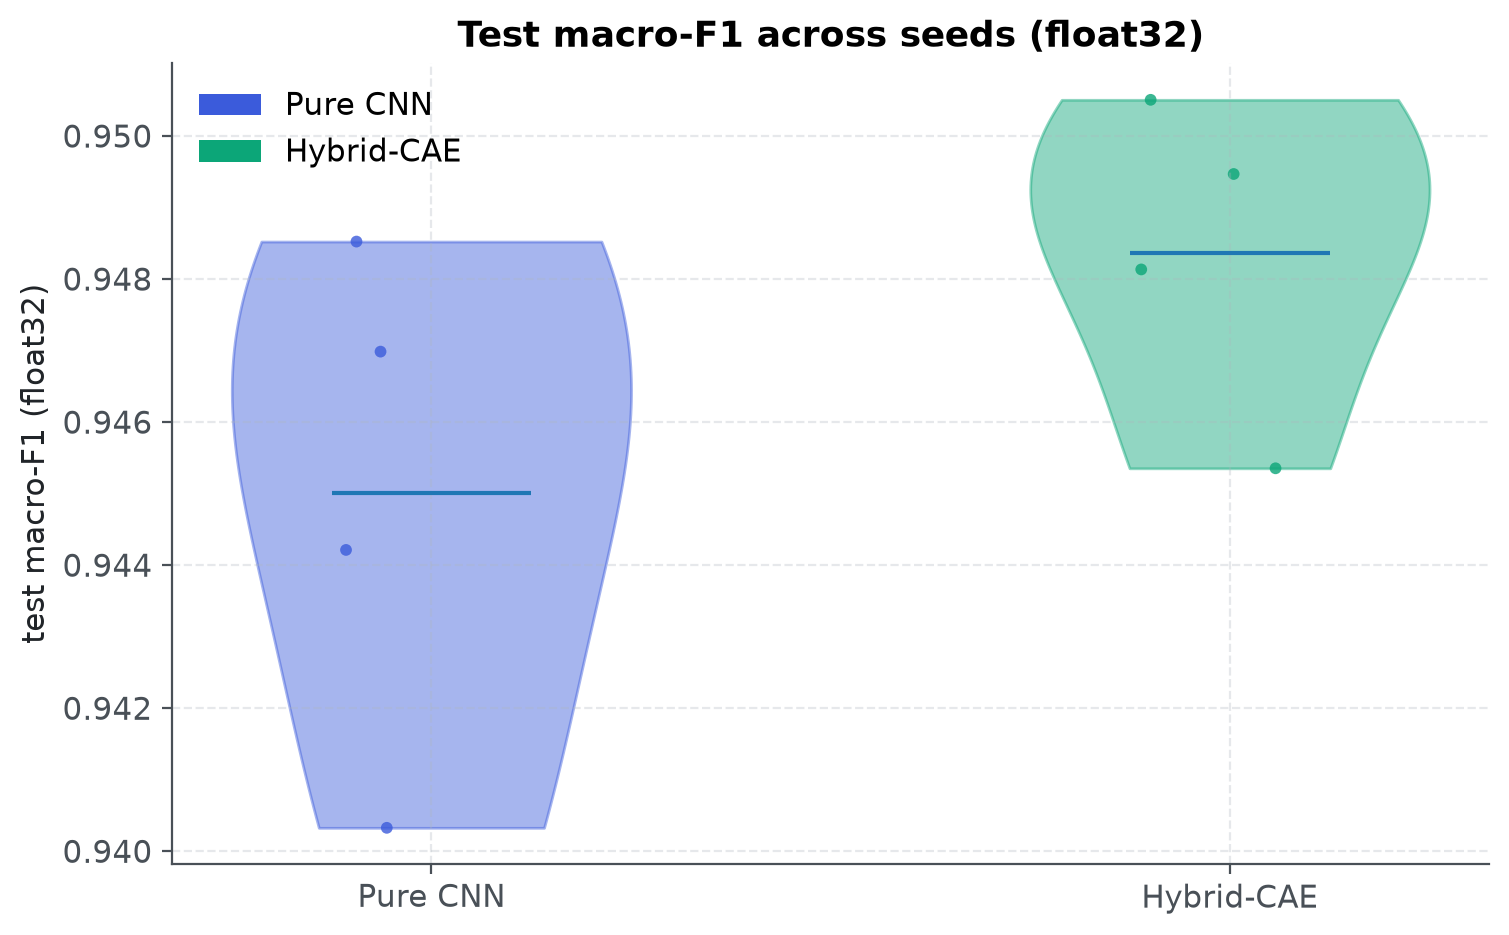

,seed,pure_cnn,hybrid,delta
0,7,0.94699,0.94535,-0.00163
1,42,0.94852,0.94947,+0.00094
2,123,0.94421,0.95051,+0.00629
3,2024,0.94033,0.94813,+0.00781


In [7]:
from eos.utils.visualization import plot_metric_distributions, save_figure

per_seed = {}
for run in bundle["runs"]:
    if run["classification"] is not None:
        per_seed.setdefault(run["mode"], {})[run["seed"]] = run["classification"]["macro_f1"]

seeds = sorted(per_seed["classifier"])
clf_scores = [per_seed["classifier"][seed] for seed in seeds]
hyb_scores = [per_seed["hybrid"][seed] for seed in seeds]
deltas = [hybrid - pure for pure, hybrid in zip(clf_scores, hyb_scores, strict=True)]
replicates = [
    run["classification"]["macro_f1"]
    for run in bundle["runs"]
    if run["mode"] == "hybrid" and run["seed"] == 42 and run["classification"] is not None
]
noise_floor = abs(replicates[0] - replicates[-1])

fig, ax = plot_metric_distributions(
    [clf_scores, hyb_scores],
    arm_names=["Pure CNN", "Hybrid-CAE"],
    metric_name="test macro-F1 (float32)",
    title="Test macro-F1 across seeds (float32)",
)
figure_path = save_figure(fig, FIGURES_DIR / "macro_f1_distributions.png")
display(Image(filename=str(figure_path)))

pd.DataFrame(
    {
        "seed": seeds,
        "pure_cnn": clf_scores,
        "hybrid": hyb_scores,
        "delta": deltas,
    }
).style.format({"pure_cnn": "{:.5f}", "hybrid": "{:.5f}", "delta": "{:+.5f}"})

In [8]:
print(f"mean paired delta      {np.mean(deltas):+.5f}  (bf16-mixed logged value: +0.00204)")
print(f"std of paired deltas   {np.std(deltas, ddof=1):.5f}")
print(f"seeds positive         {sum(1 for d in deltas if d > 0)}/{len(deltas)}")
print(f"run-to-run noise floor {noise_floor:.5f}  (same seed, two trainings, float32)")
print("evaluation regime      float32 (finding F-002: bf16 logging shifts pairs by up to 0.0048)")

mean paired delta      +0.00335  (bf16-mixed logged value: +0.00204)
std of paired deltas   0.00444
seeds positive         3/4
run-to-run noise floor 0.00153  (same seed, two trainings, float32)
evaluation regime      float32 (finding F-002: bf16 logging shifts pairs by up to 0.0048)


## Per-class analysis — the decisive slice

The hypothesis predicts where the gain should appear. Per-class F1 is far more
sensitive to mechanism than aggregate macro-F1.

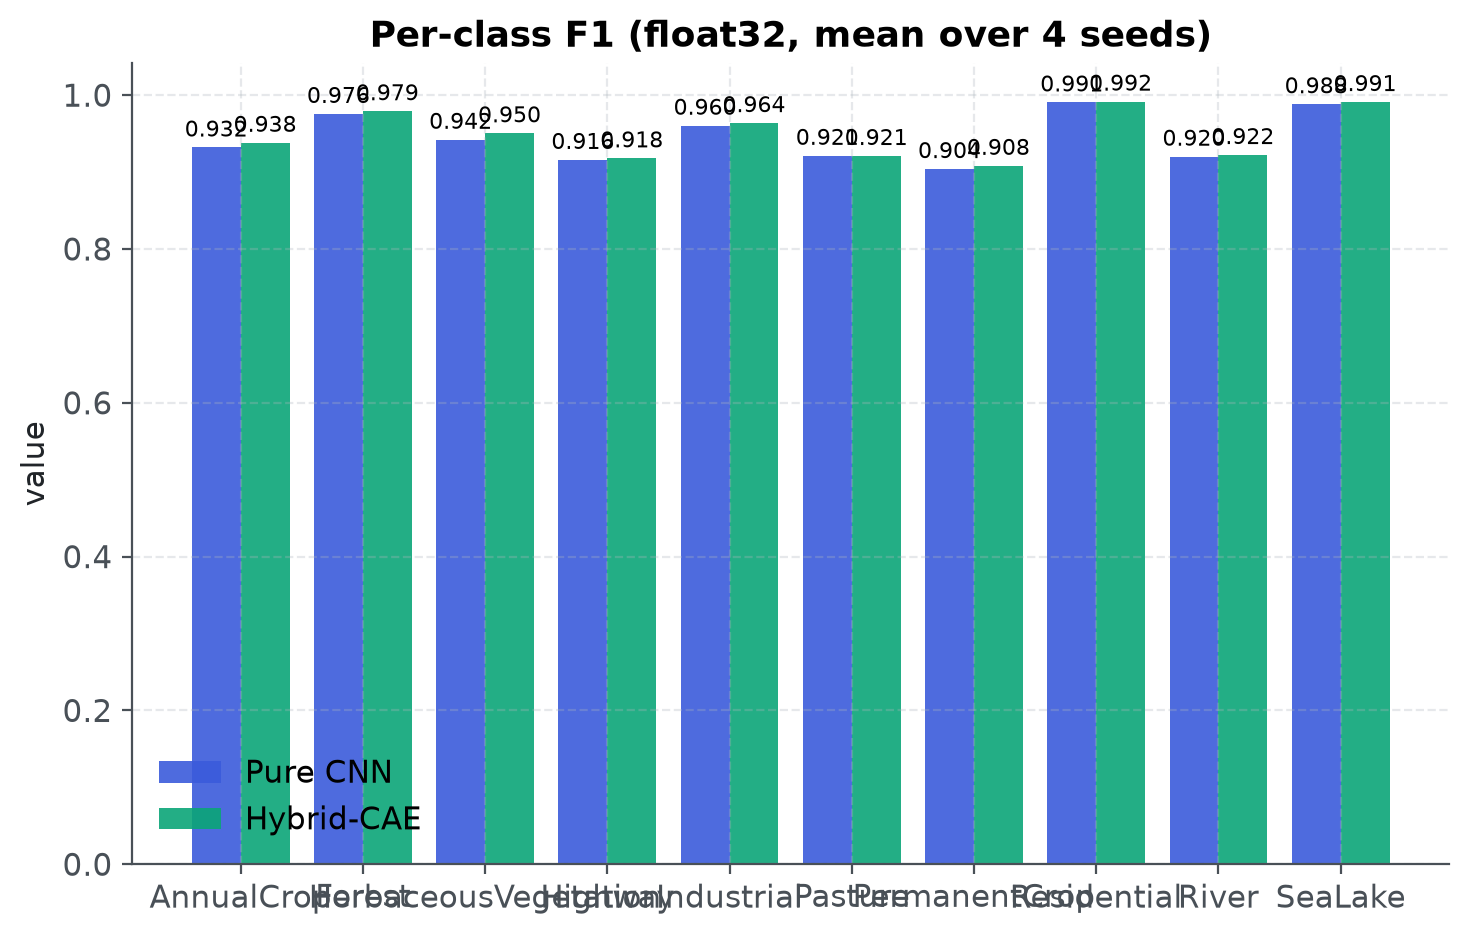

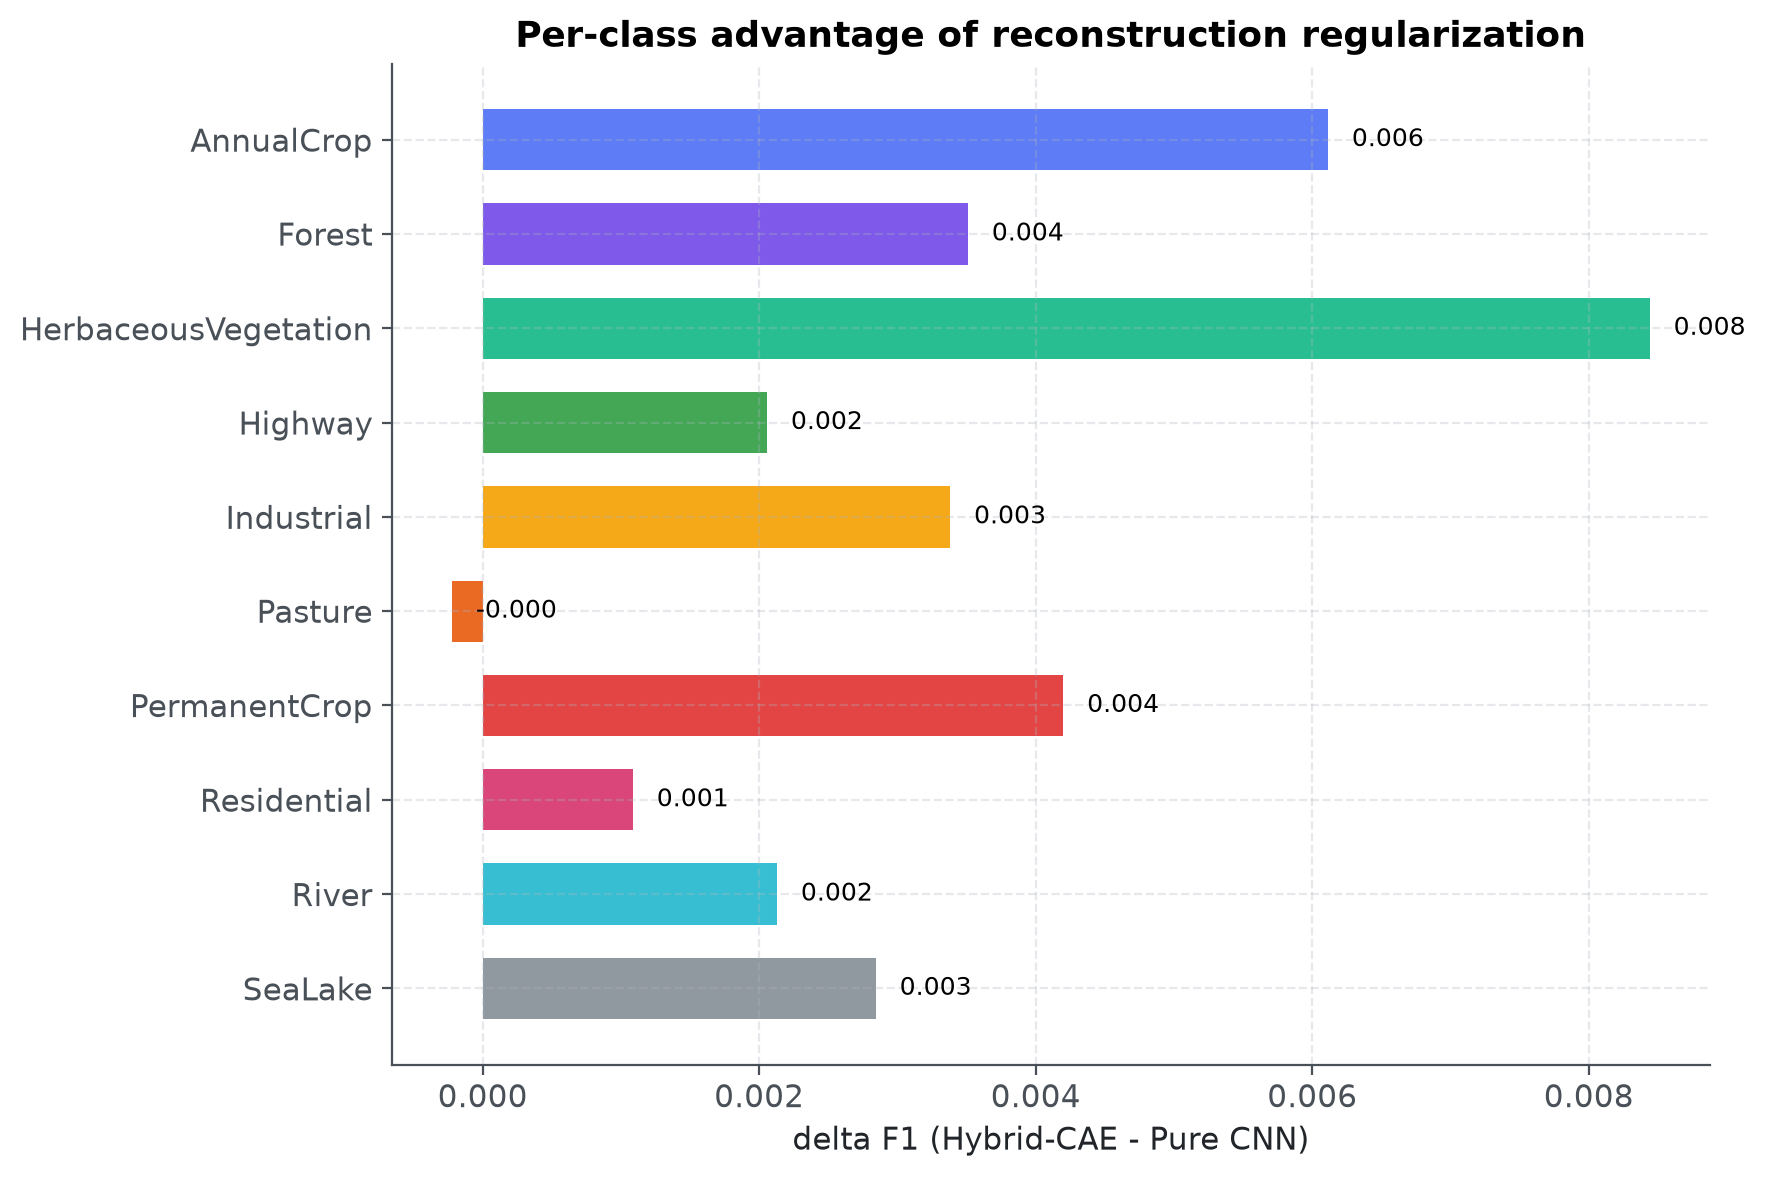

,class,pure_cnn,hybrid,delta
2,HerbaceousVegetation,0.9421,0.9505,+0.0084
0,AnnualCrop,0.9320,0.9381,+0.0061
6,PermanentCrop,0.9040,0.9082,+0.0042
1,Forest,0.9757,0.9792,+0.0035
4,Industrial,0.9604,0.9637,+0.0034
9,SeaLake,0.9883,0.9911,+0.0028
8,River,0.9201,0.9222,+0.0021
3,Highway,0.9159,0.9179,+0.0021
7,Residential,0.9906,0.9917,+0.0011
5,Pasture,0.9212,0.9210,-0.0002


In [9]:
from eos.utils.visualization import plot_ablation_bars, plot_class_metrics_bar

per_class = {}
for run in bundle["runs"]:
    if run["classification"] is not None:
        per_class.setdefault(run["mode"], {})[run["seed"]] = run["classification"]["per_class_f1"]

mean_clf = {
    name: float(np.mean([per_class["classifier"][seed][name] for seed in seeds]))
    for name in class_names
}
mean_hyb = {
    name: float(np.mean([per_class["hybrid"][seed][name] for seed in seeds]))
    for name in class_names
}
delta_values = [mean_hyb[name] - mean_clf[name] for name in class_names]

fig, ax = plot_ablation_bars(
    {"Pure CNN": mean_clf, "Hybrid-CAE": mean_hyb},
    title="Per-class F1 (float32, mean over 4 seeds)",
)
figure_path = save_figure(fig, FIGURES_DIR / "per_class_f1.png")
display(Image(filename=str(figure_path)))

fig, ax = plot_class_metrics_bar(
    delta_values,
    metric_name="delta F1 (Hybrid-CAE - Pure CNN)",
    class_names=class_names,
    title="Per-class advantage of reconstruction regularization",
)
figure_path = save_figure(fig, FIGURES_DIR / "per_class_delta.png")
display(Image(filename=str(figure_path)))

pd.DataFrame(
    {
        "class": class_names,
        "pure_cnn": [mean_clf[name] for name in class_names],
        "hybrid": [mean_hyb[name] for name in class_names],
        "delta": delta_values,
    }
).sort_values("delta", ascending=False).style.format(
    {"pure_cnn": "{:.4f}", "hybrid": "{:.4f}", "delta": "{:+.4f}"}
)

## Confusion matrices

Normalized confusion matrices of the showcase seed (float32). Rows are true
classes, columns are predictions.

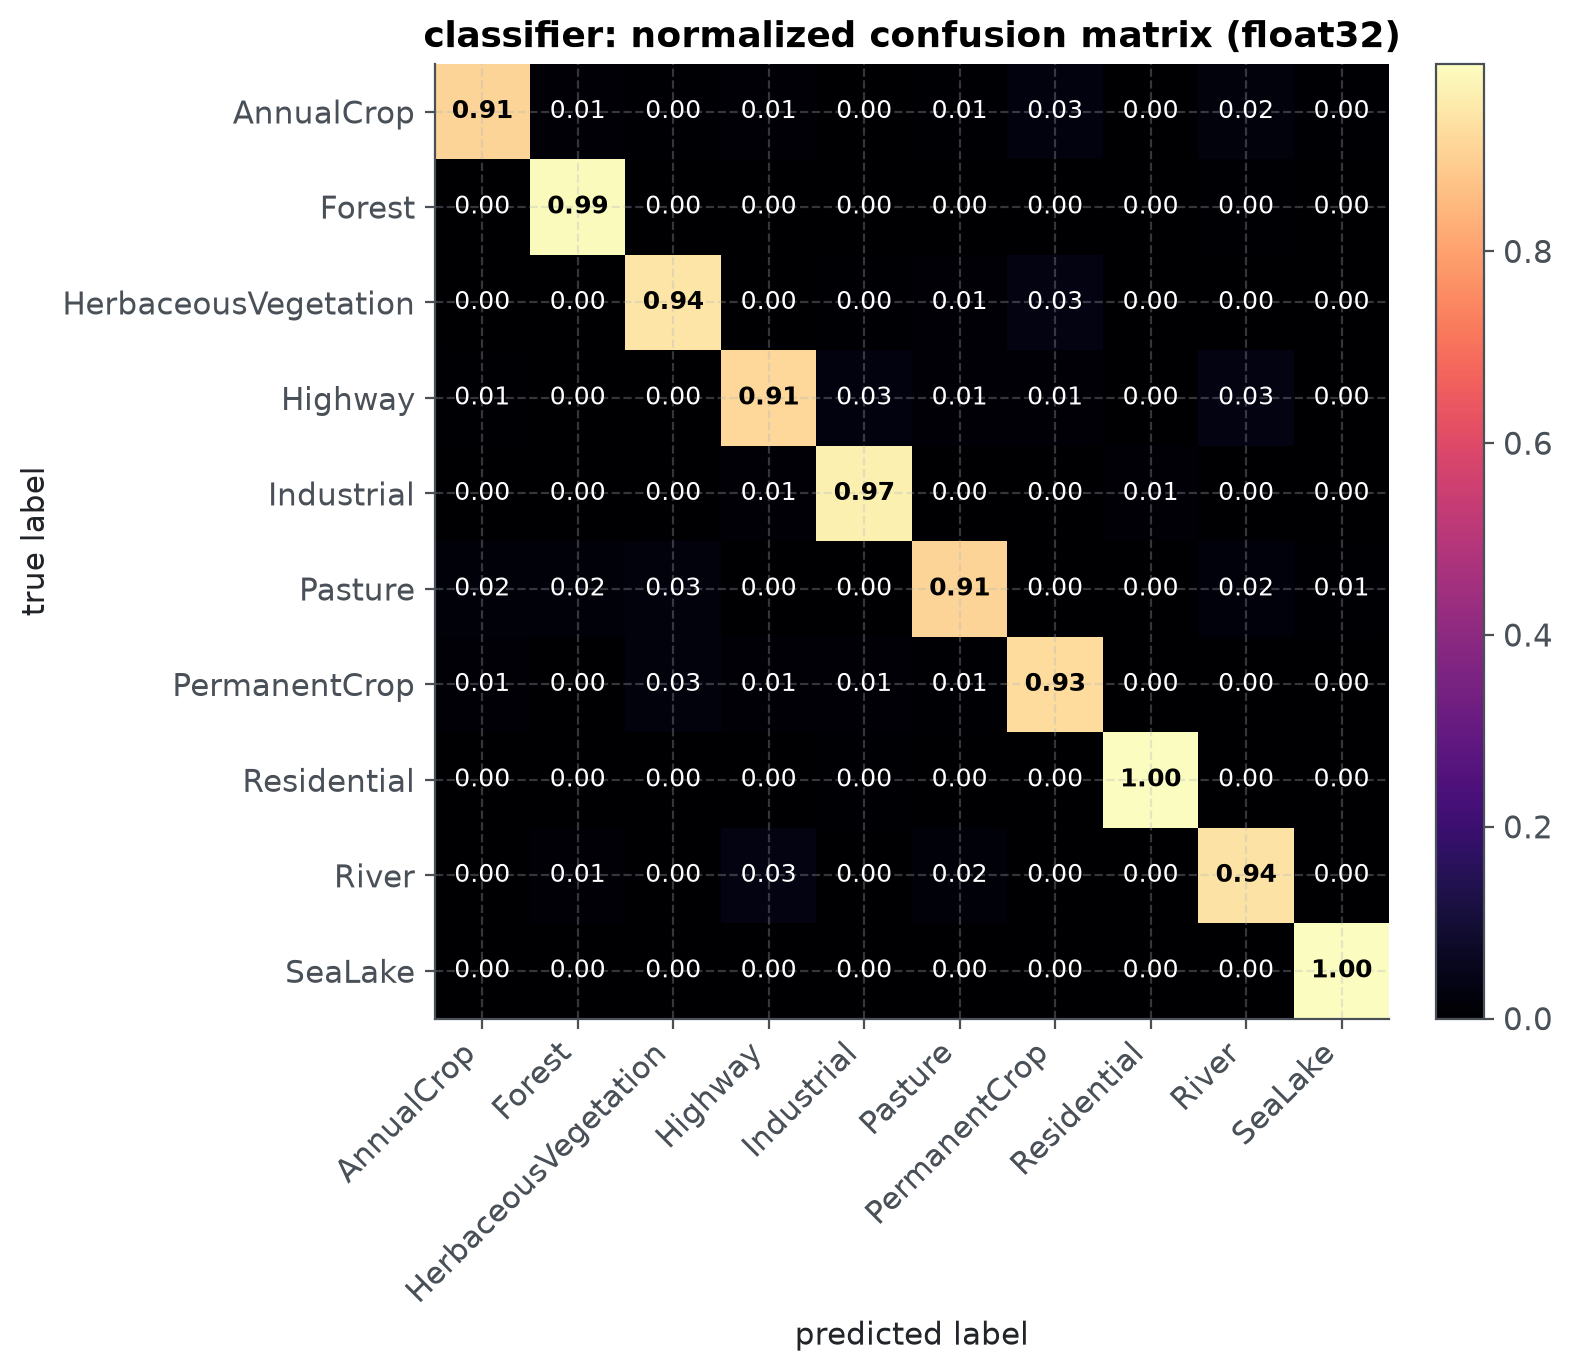

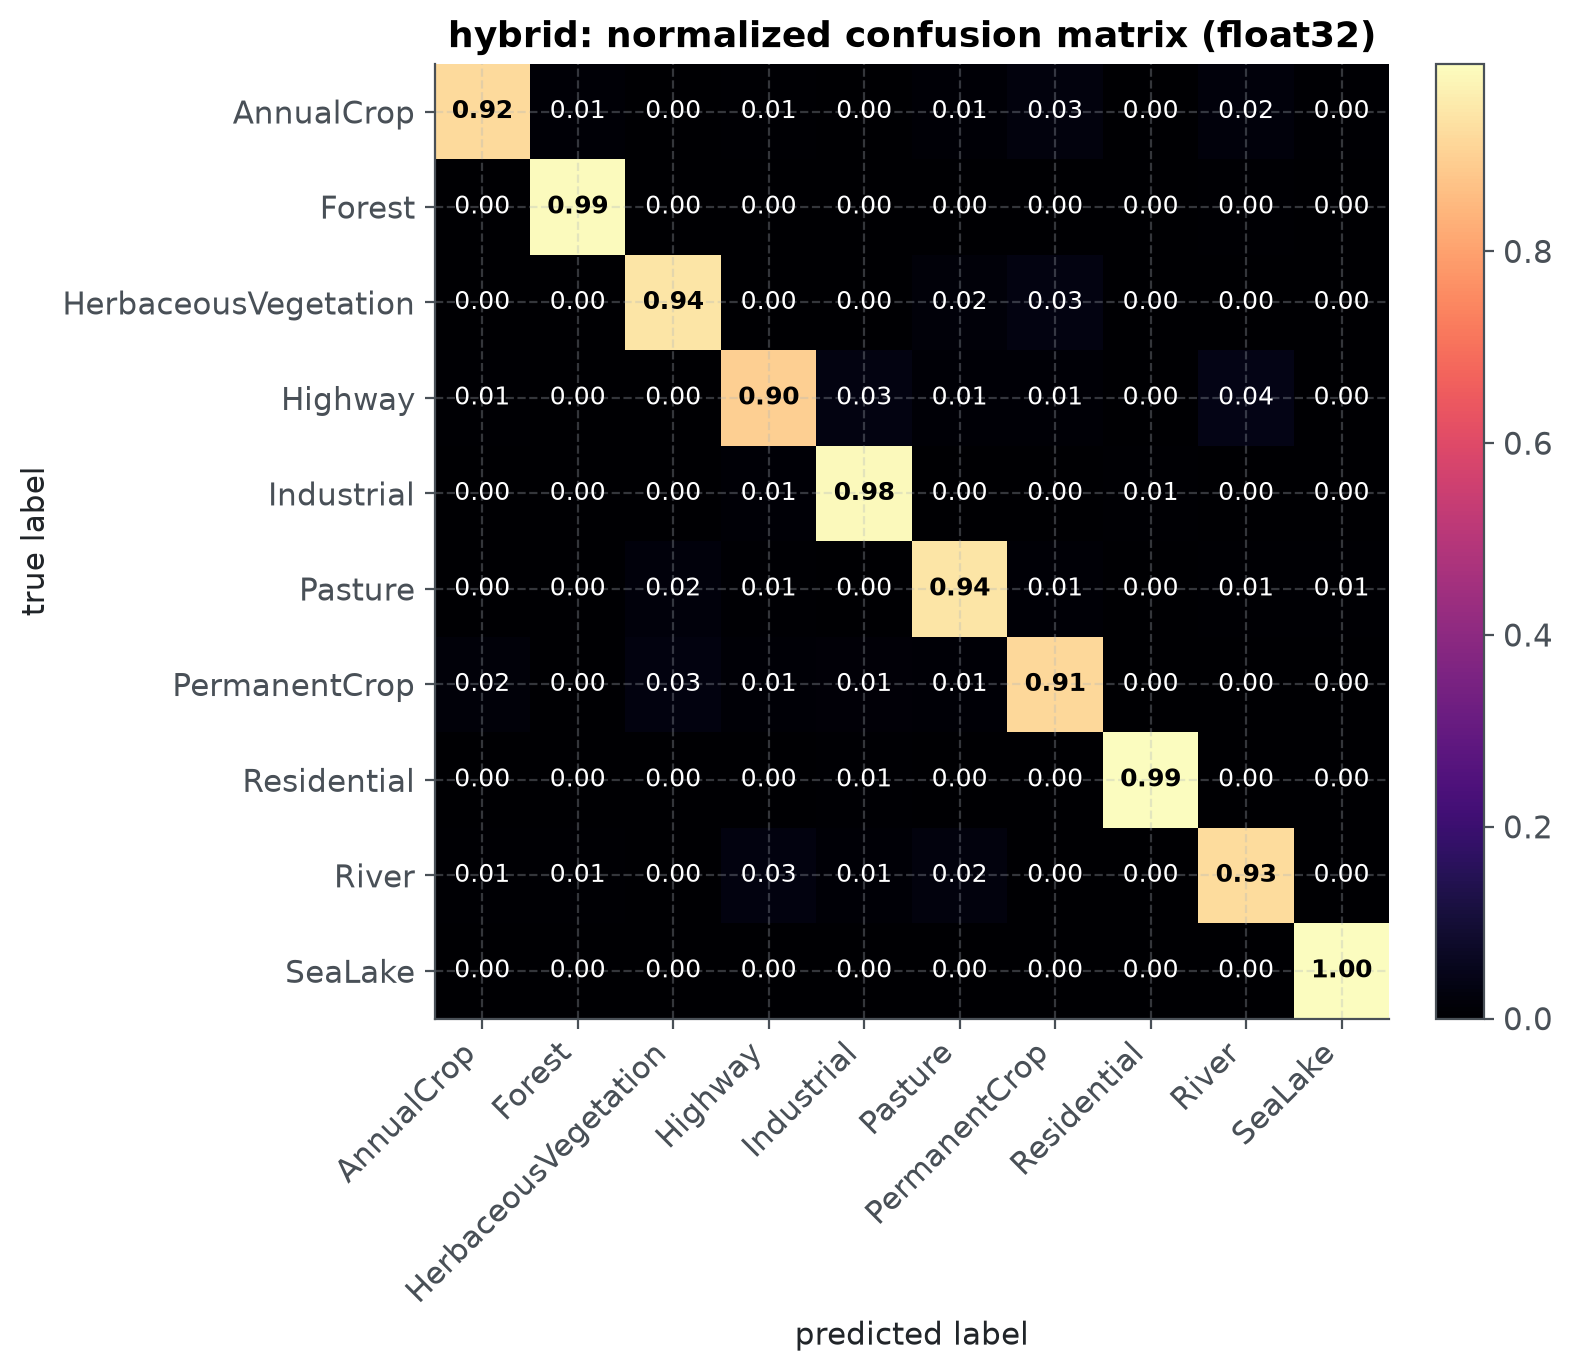

In [10]:
from eos.utils.visualization import plot_confusion_matrix

for mode in ("classifier", "hybrid"):
    run = max(
        (r for r in bundle["runs"] if r["mode"] == mode and r["seed"] == 42),
        key=lambda r: r["run_name"],
    )
    matrix = np.array(run["classification"]["confusion"], dtype=np.int64)
    fig, ax = plot_confusion_matrix(
        matrix,
        class_names=class_names,
        normalize=True,
        title=f"{mode}: normalized confusion matrix (float32)",
    )
    figure_path = save_figure(fig, FIGURES_DIR / f"confusion_{mode}.png")
    display(Image(filename=str(figure_path)))

## Reconstruction grids and residual heatmaps

Original versus reconstructed patches across all 10 classes, and the absolute
residual maps $|X - \hat{X}|$. The autoencoder arm sets the reconstruction
ceiling; the hybrid pays part of it for classification accuracy.

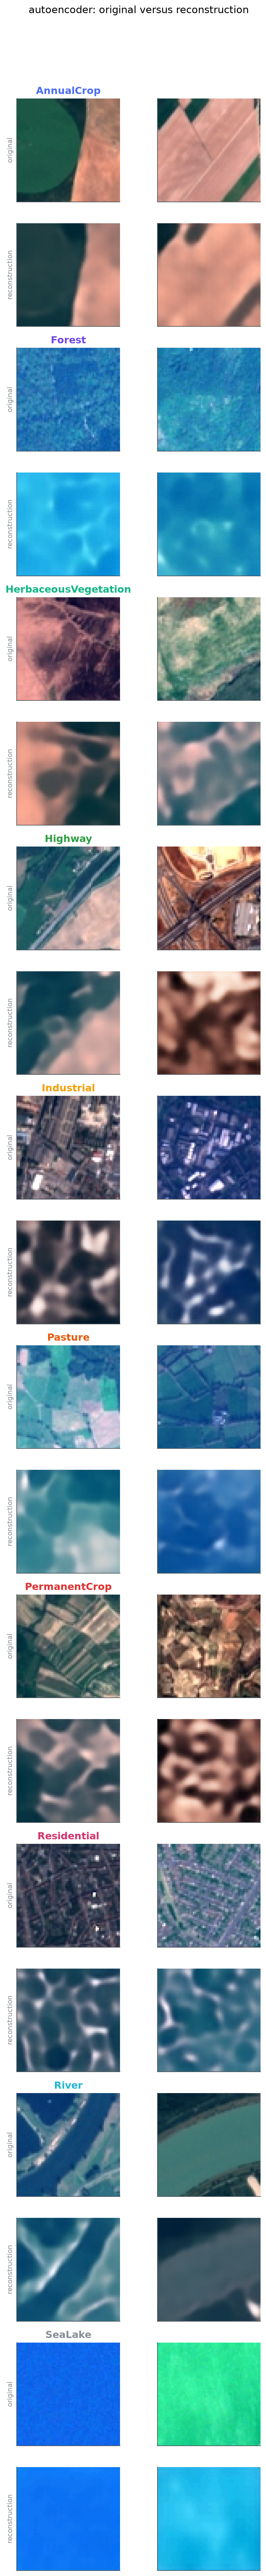

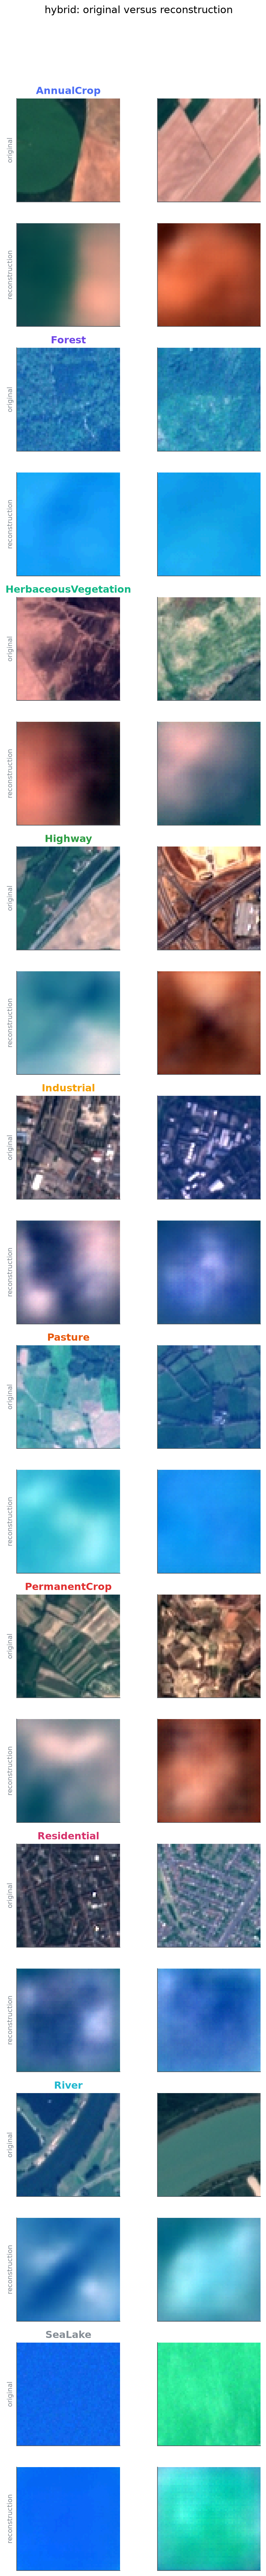

In [11]:
from eos.utils.visualization import plot_patch_grid, plot_residual_heatmaps

samples = {
    mode: np.load(EVIDENCE_DIR / f"recon_samples_{mode}.npz") for mode in ("autoencoder", "hybrid")
}

for mode, data in samples.items():
    fig, axes = plot_patch_grid(
        data["originals"],
        data["reconstructions"],
        data["labels"],
        class_names=class_names,
        max_per_class=2,
        title=f"{mode}: original versus reconstruction",
    )
    figure_path = save_figure(fig, FIGURES_DIR / f"patch_grid_{mode}.png")
    display(Image(filename=str(figure_path)))

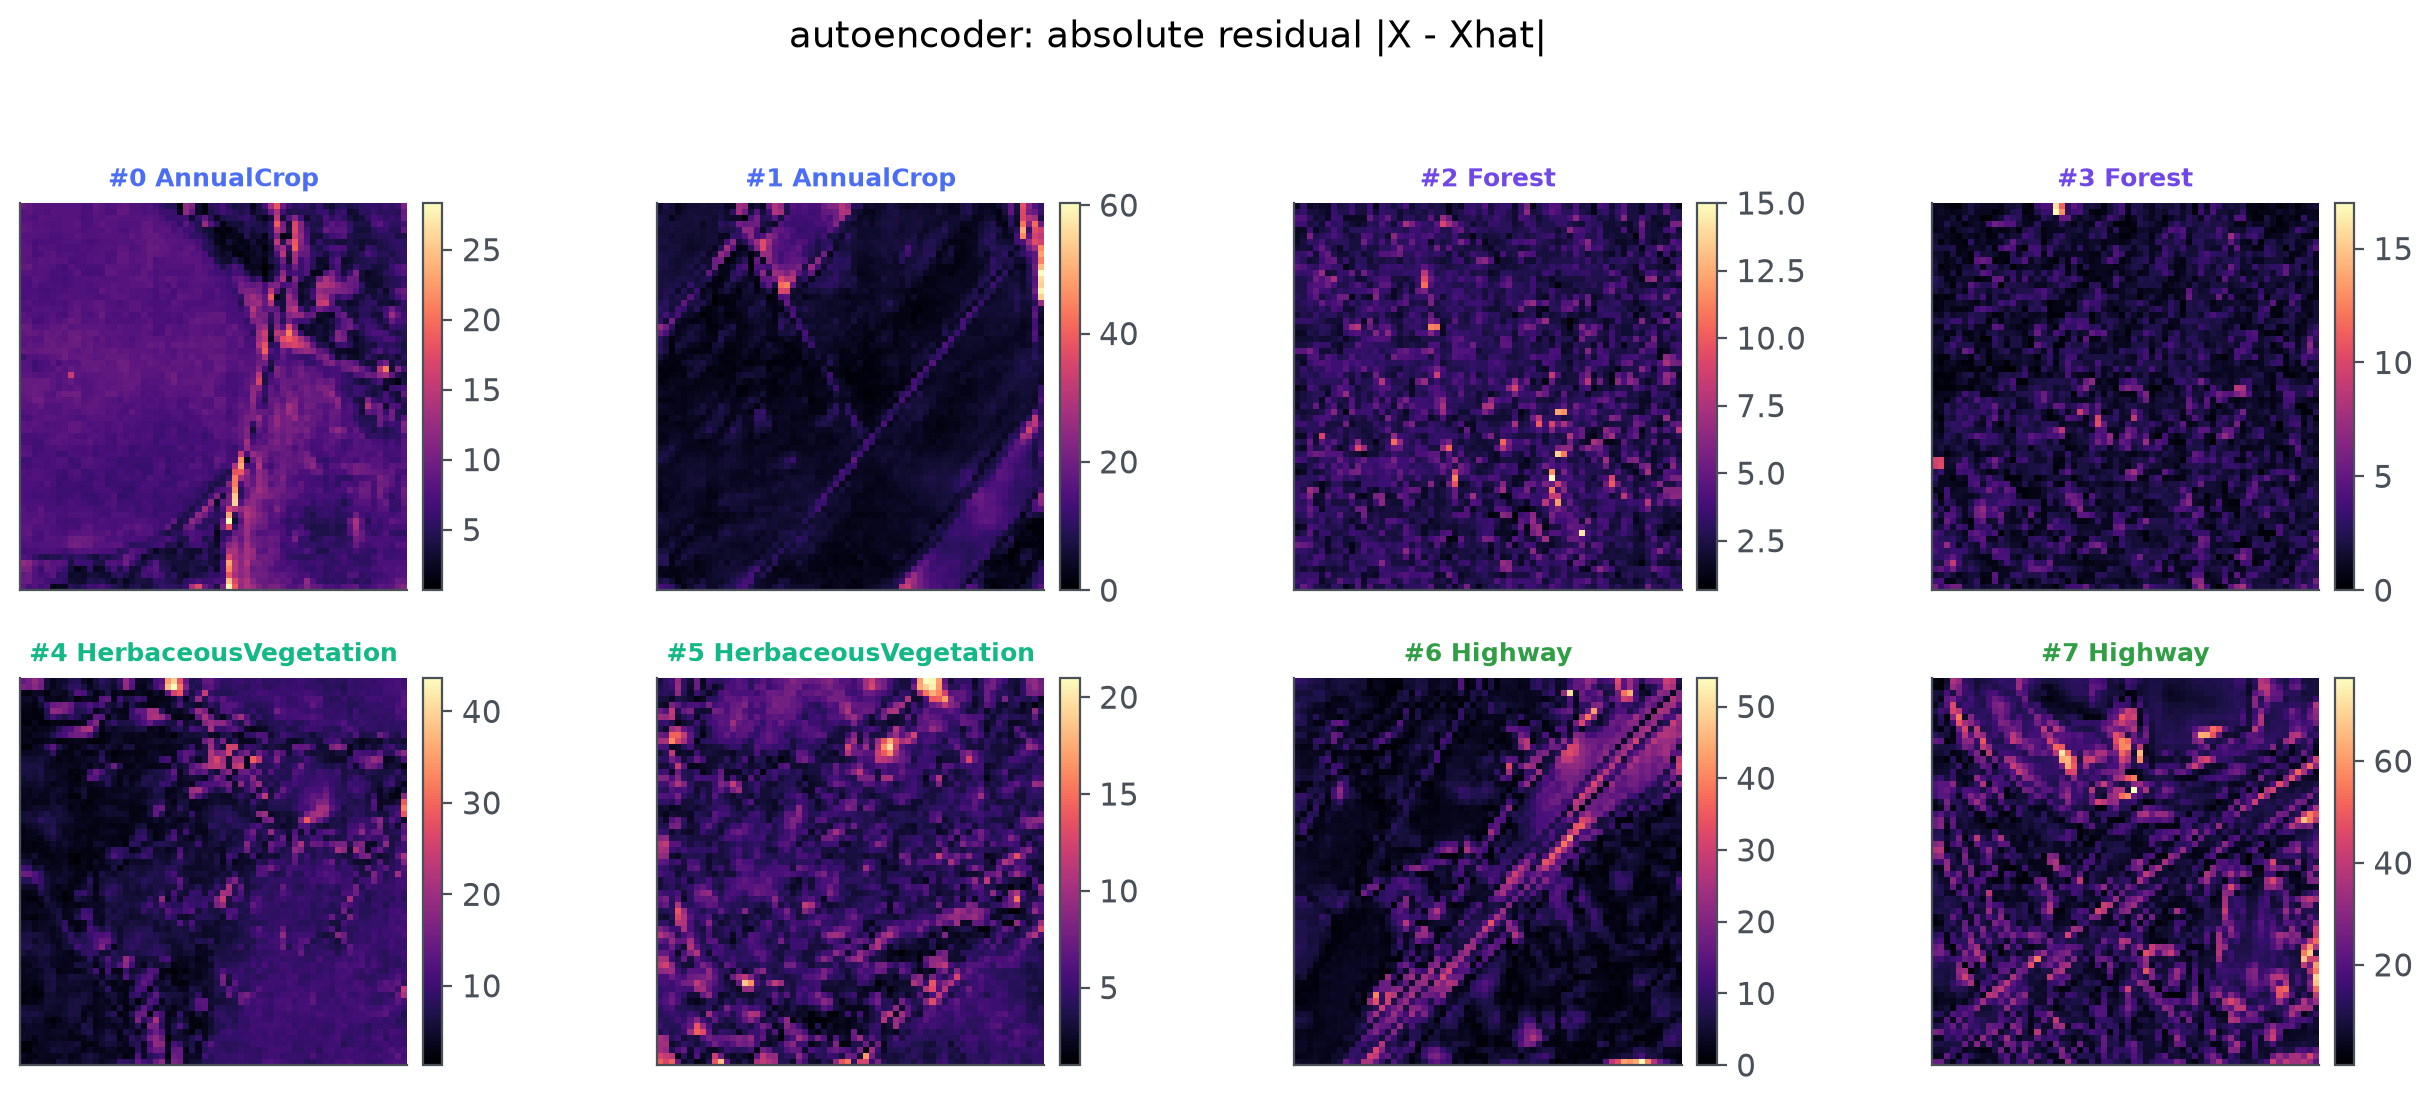

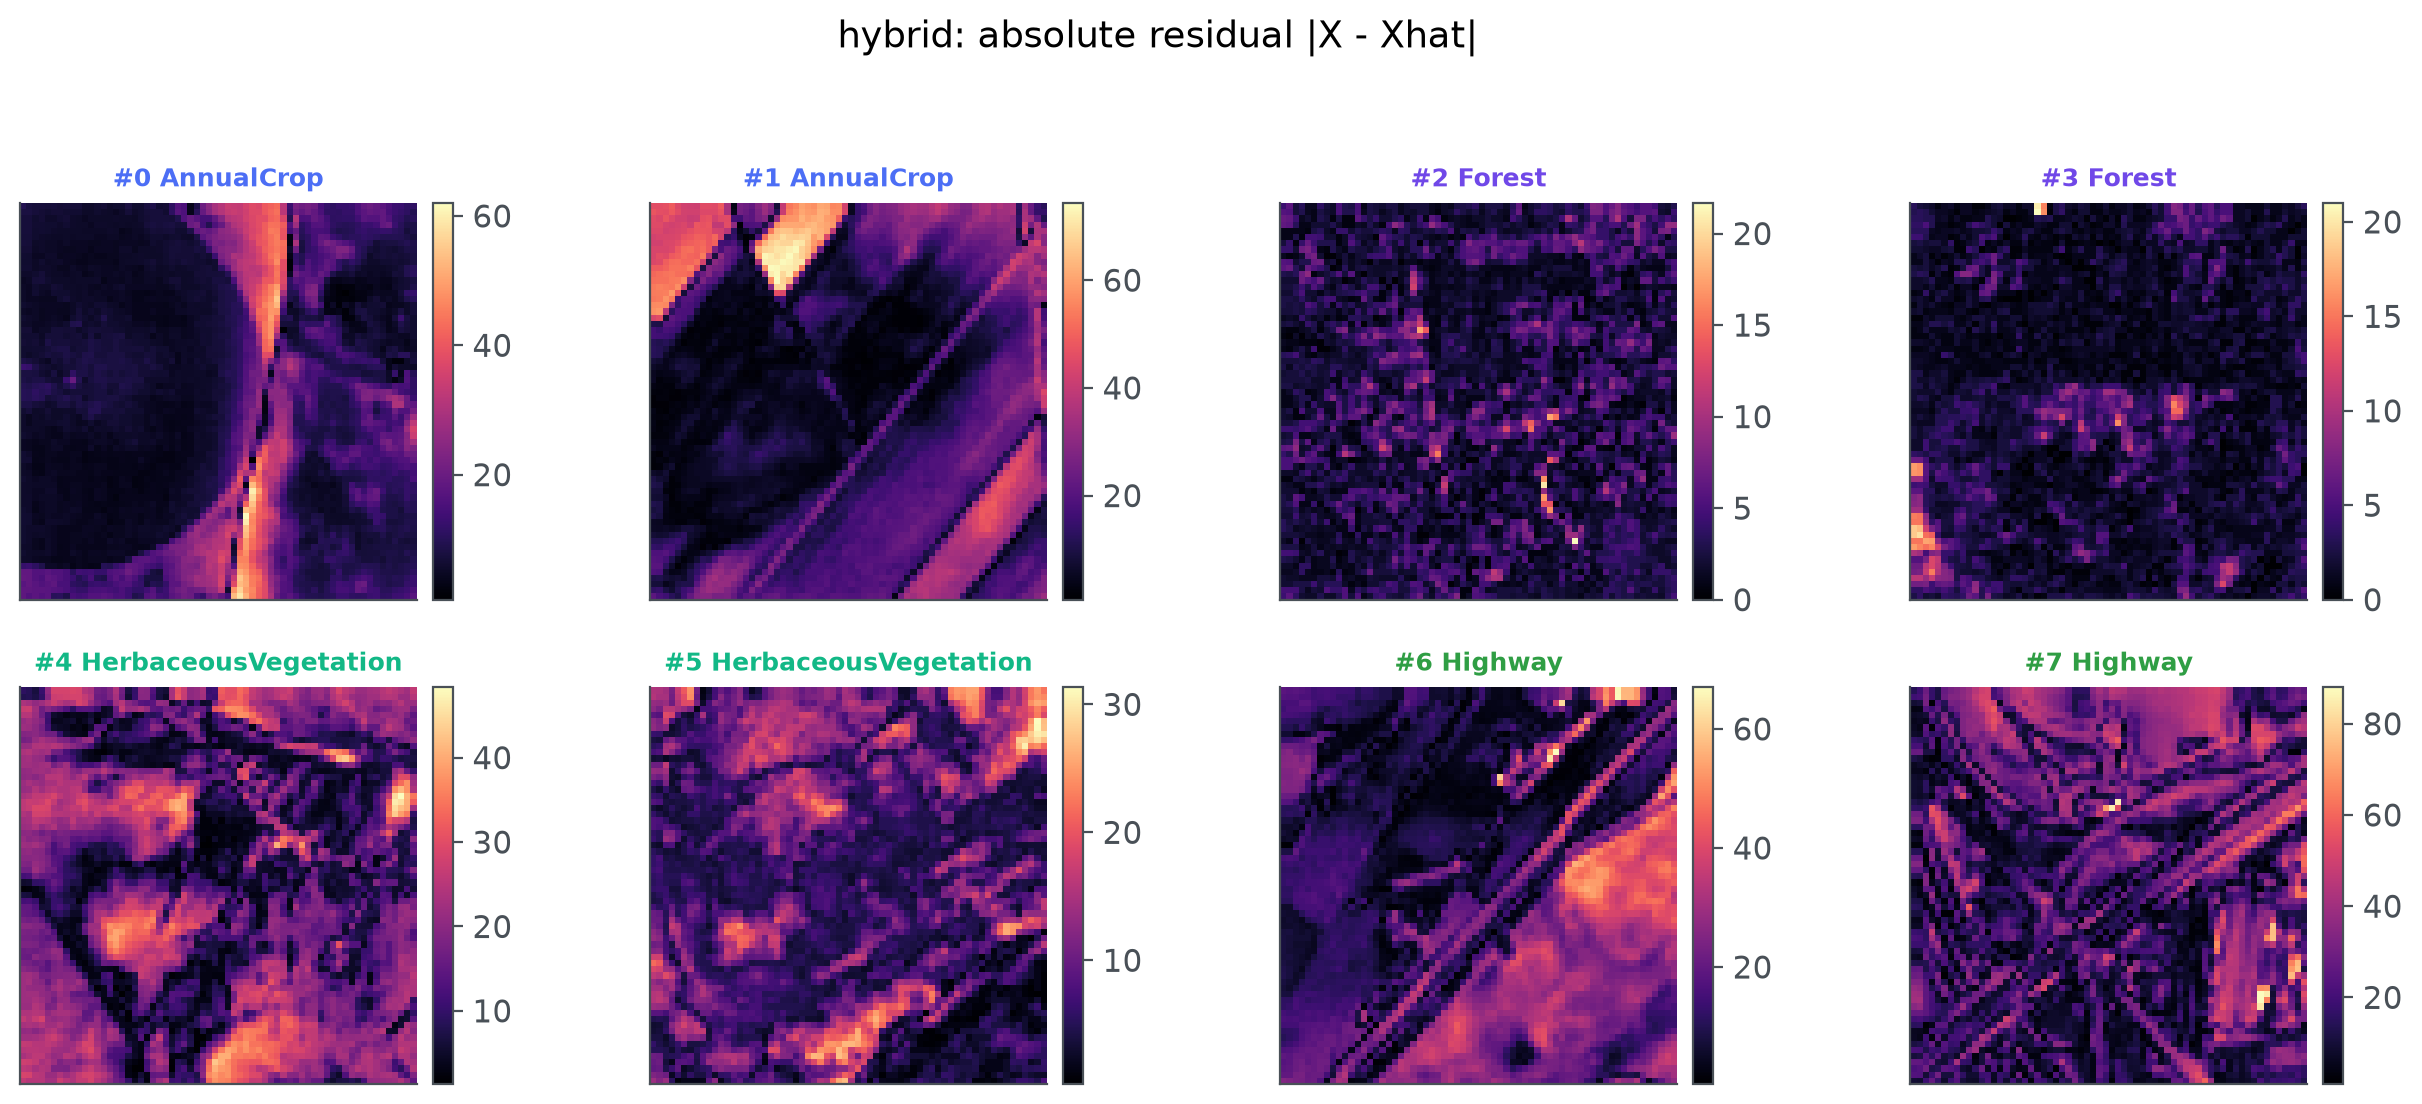

In [12]:
for mode, data in samples.items():
    fig, axes = plot_residual_heatmaps(
        data["originals"],
        data["reconstructions"],
        data["labels"],
        class_names=class_names,
        max_samples=8,
        title=f"{mode}: absolute residual |X - Xhat|",
    )
    figure_path = save_figure(fig, FIGURES_DIR / f"residuals_{mode}.png")
    display(Image(filename=str(figure_path)))

## Latent manifold projections

The bottleneck $z \in \mathbb{R}^{128}$ of the showcase seed, projected with
PCA and t-SNE. The comparison to watch: cluster separation of the Pure CNN
encoder versus the Hybrid-CAE encoder.

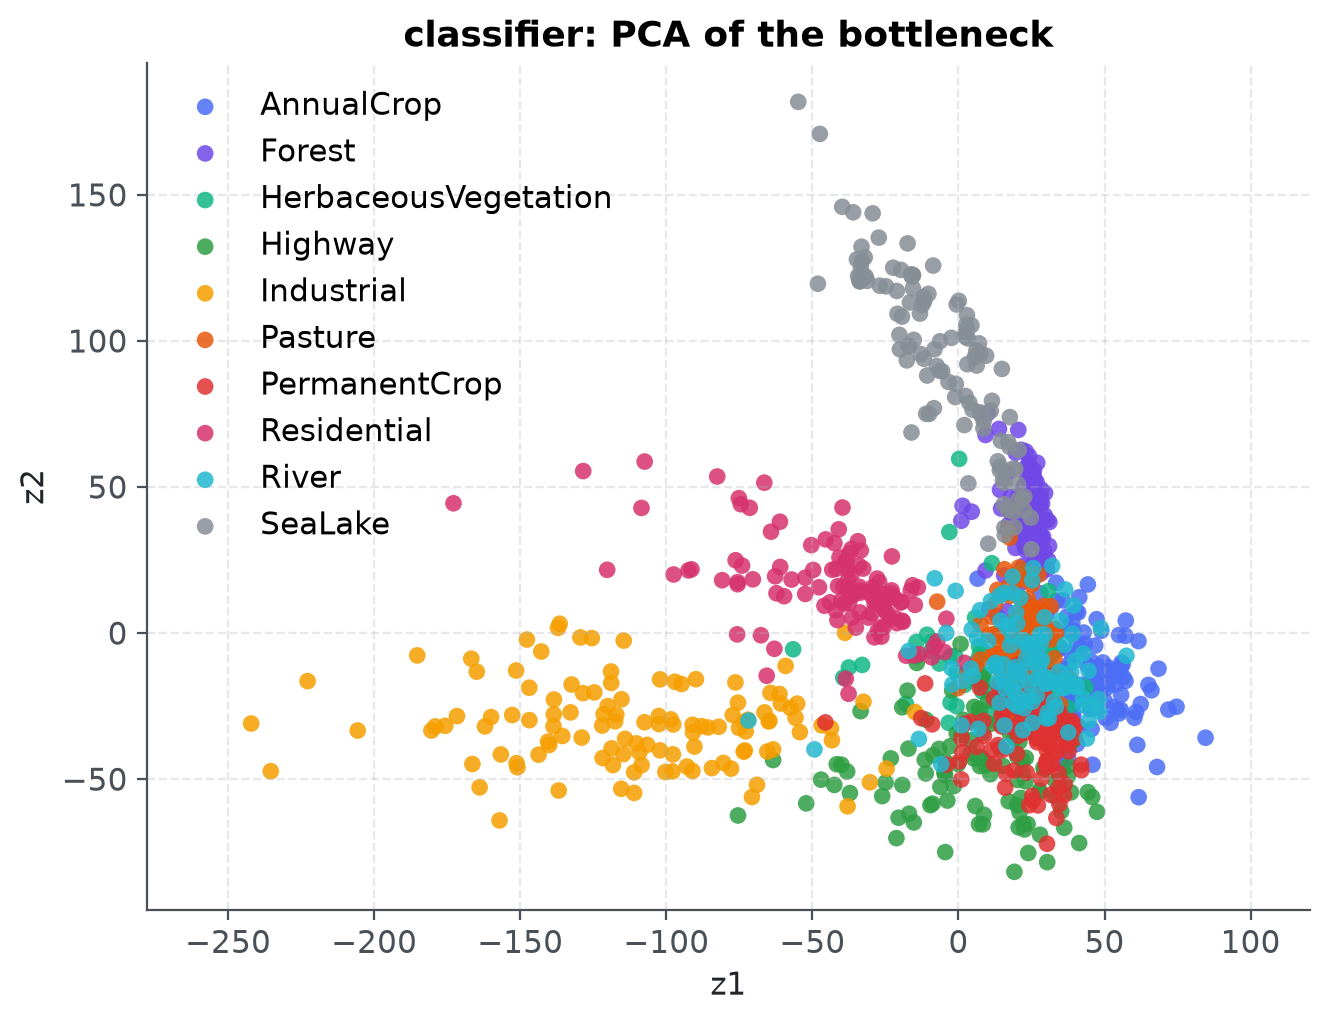

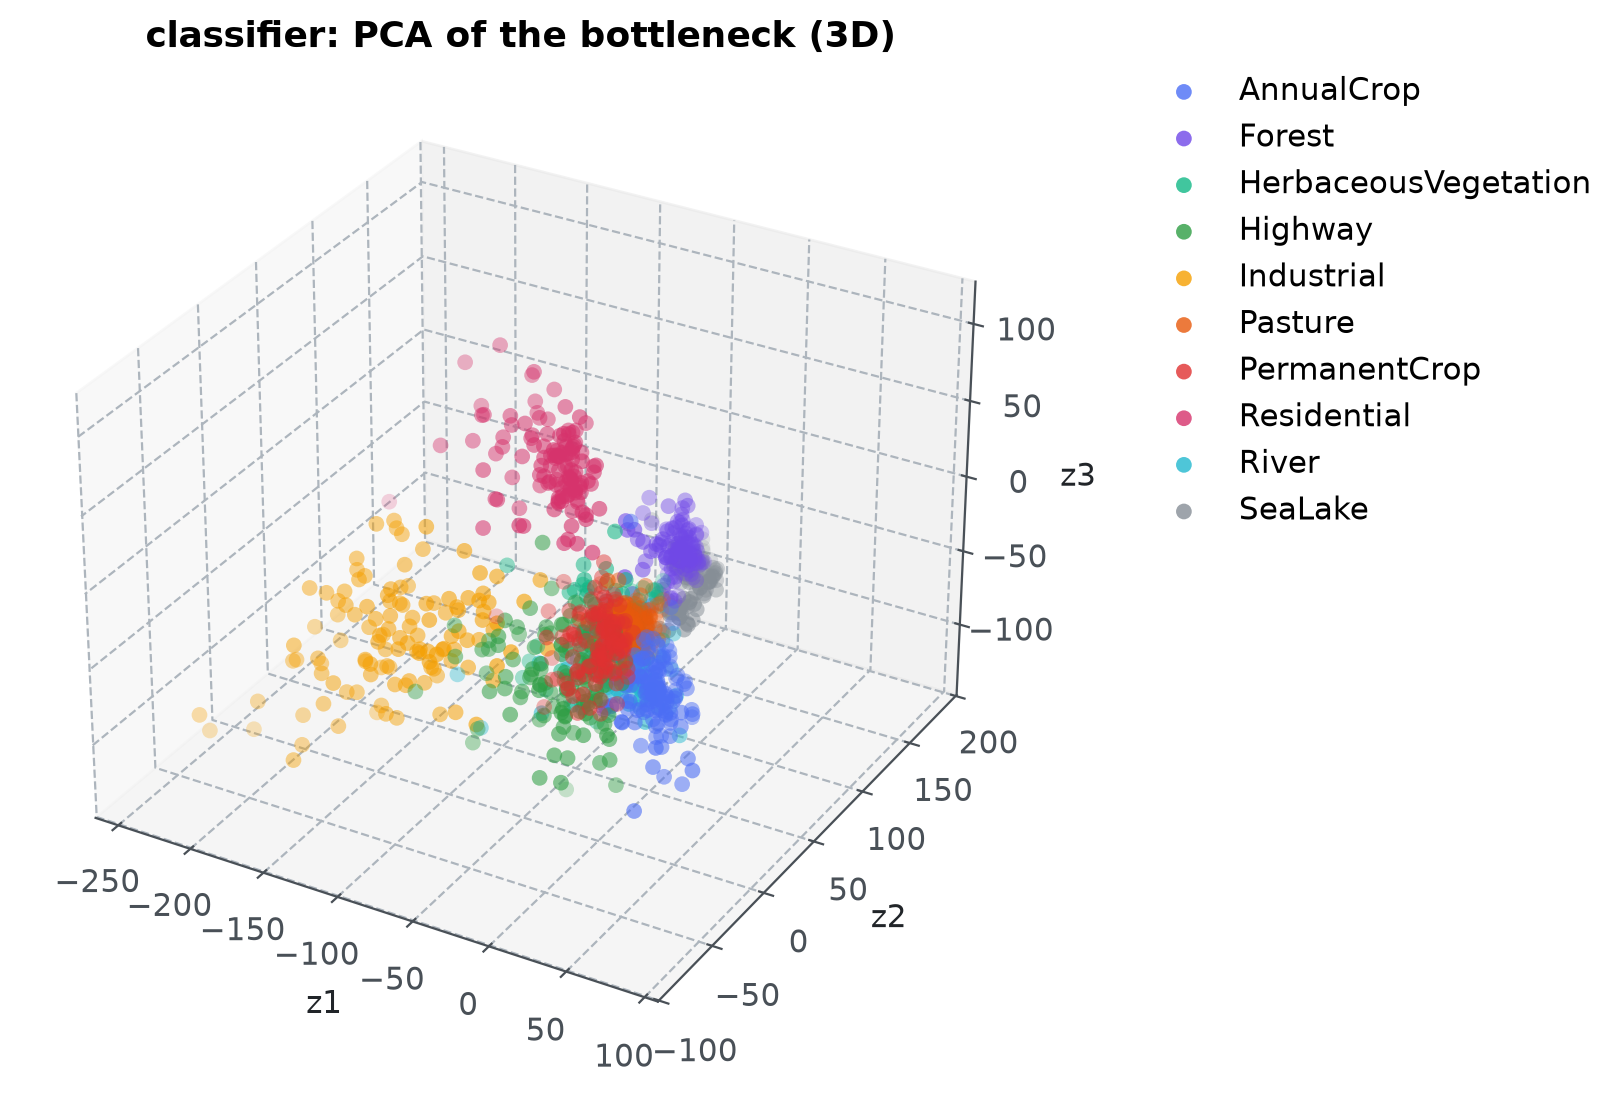

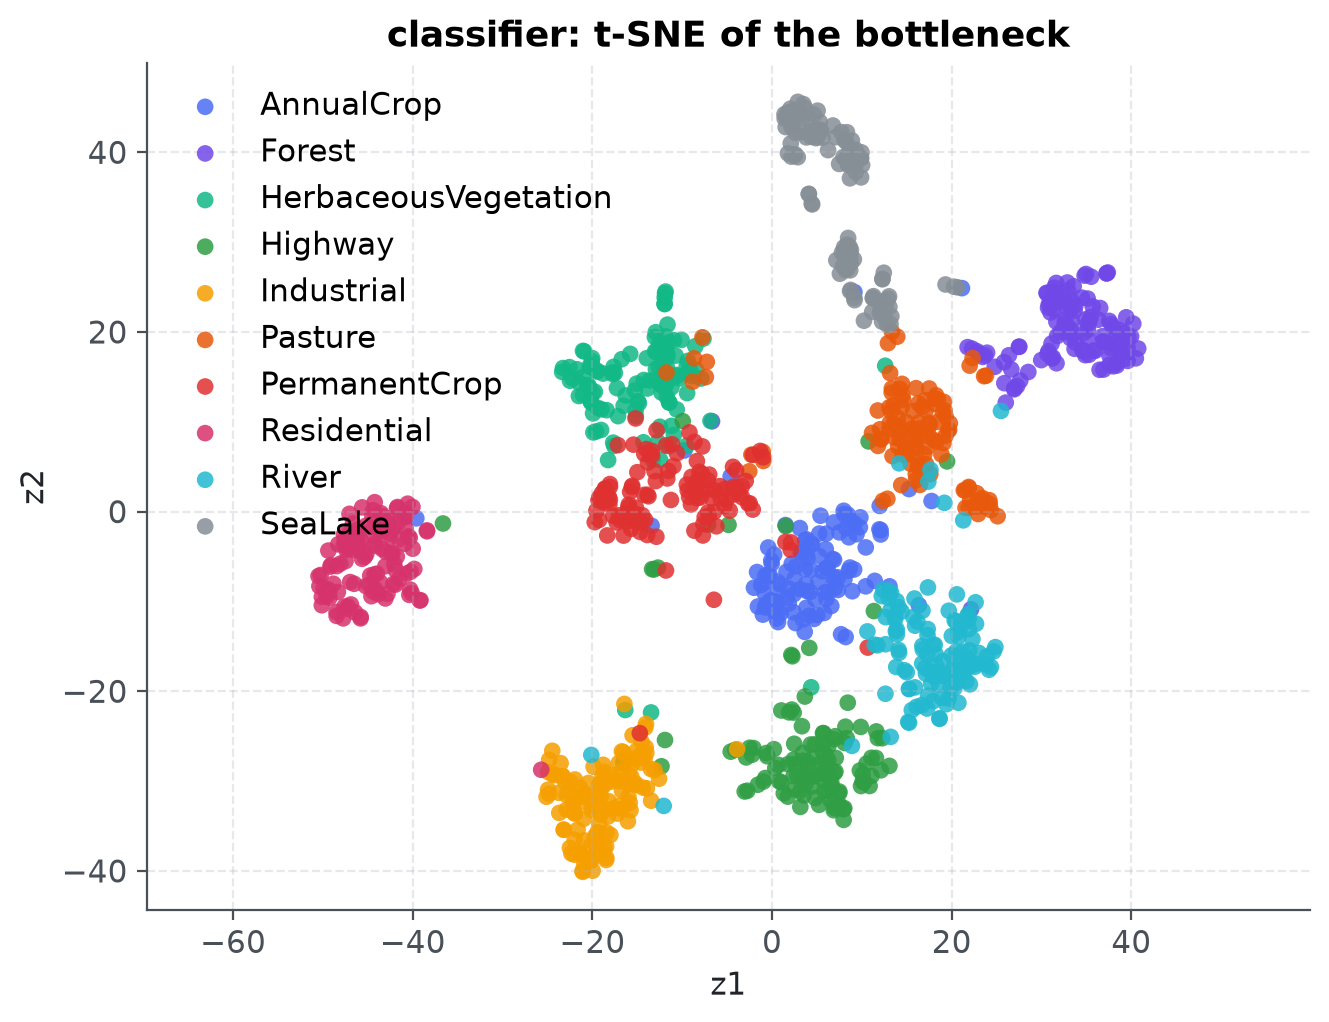

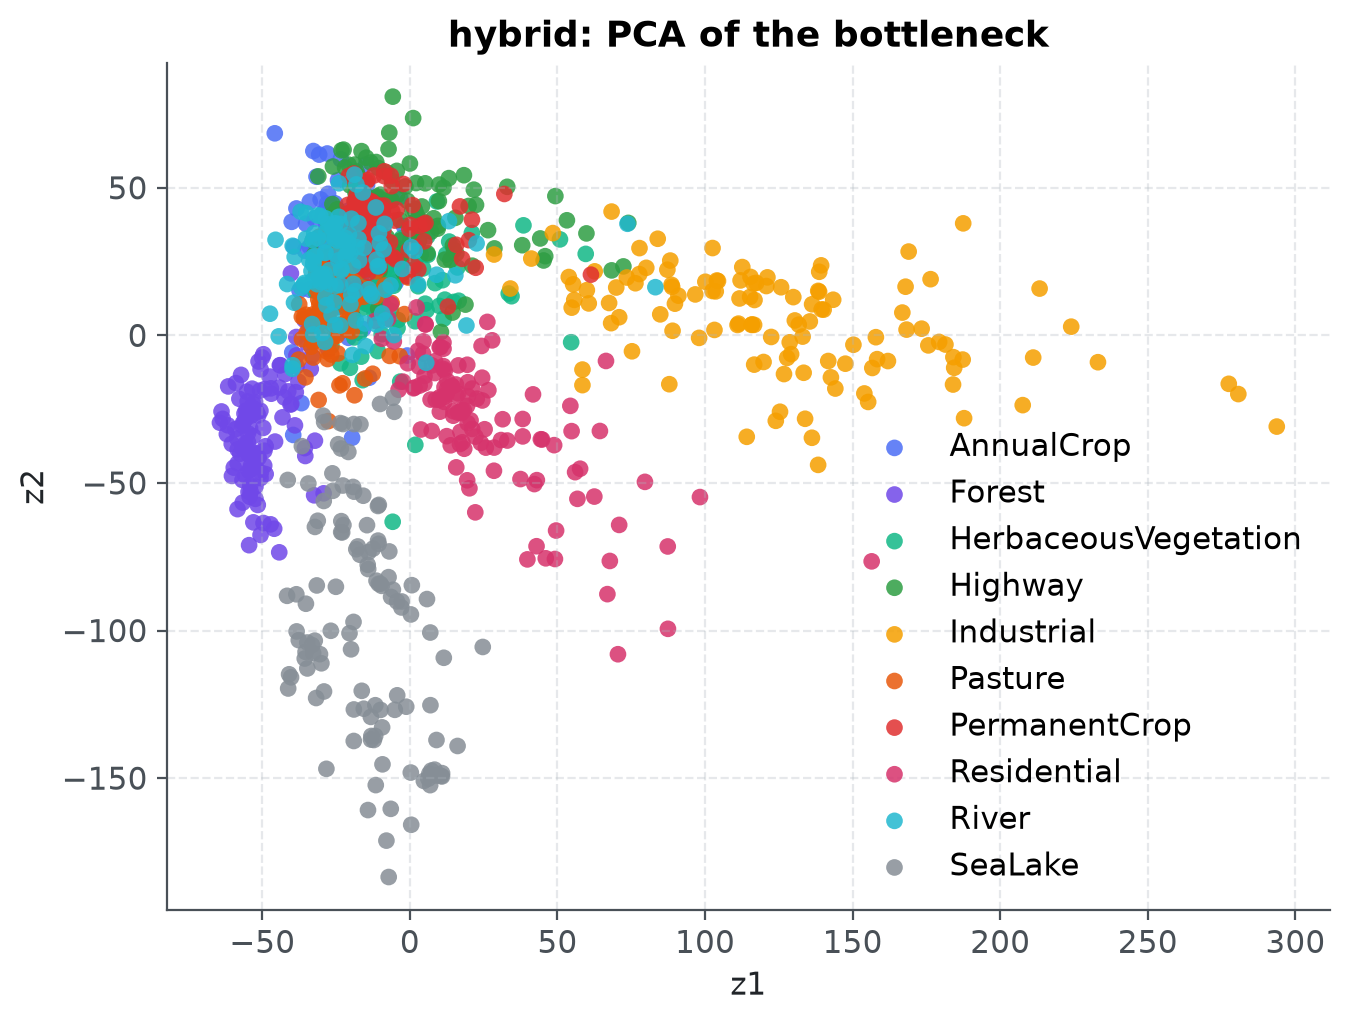

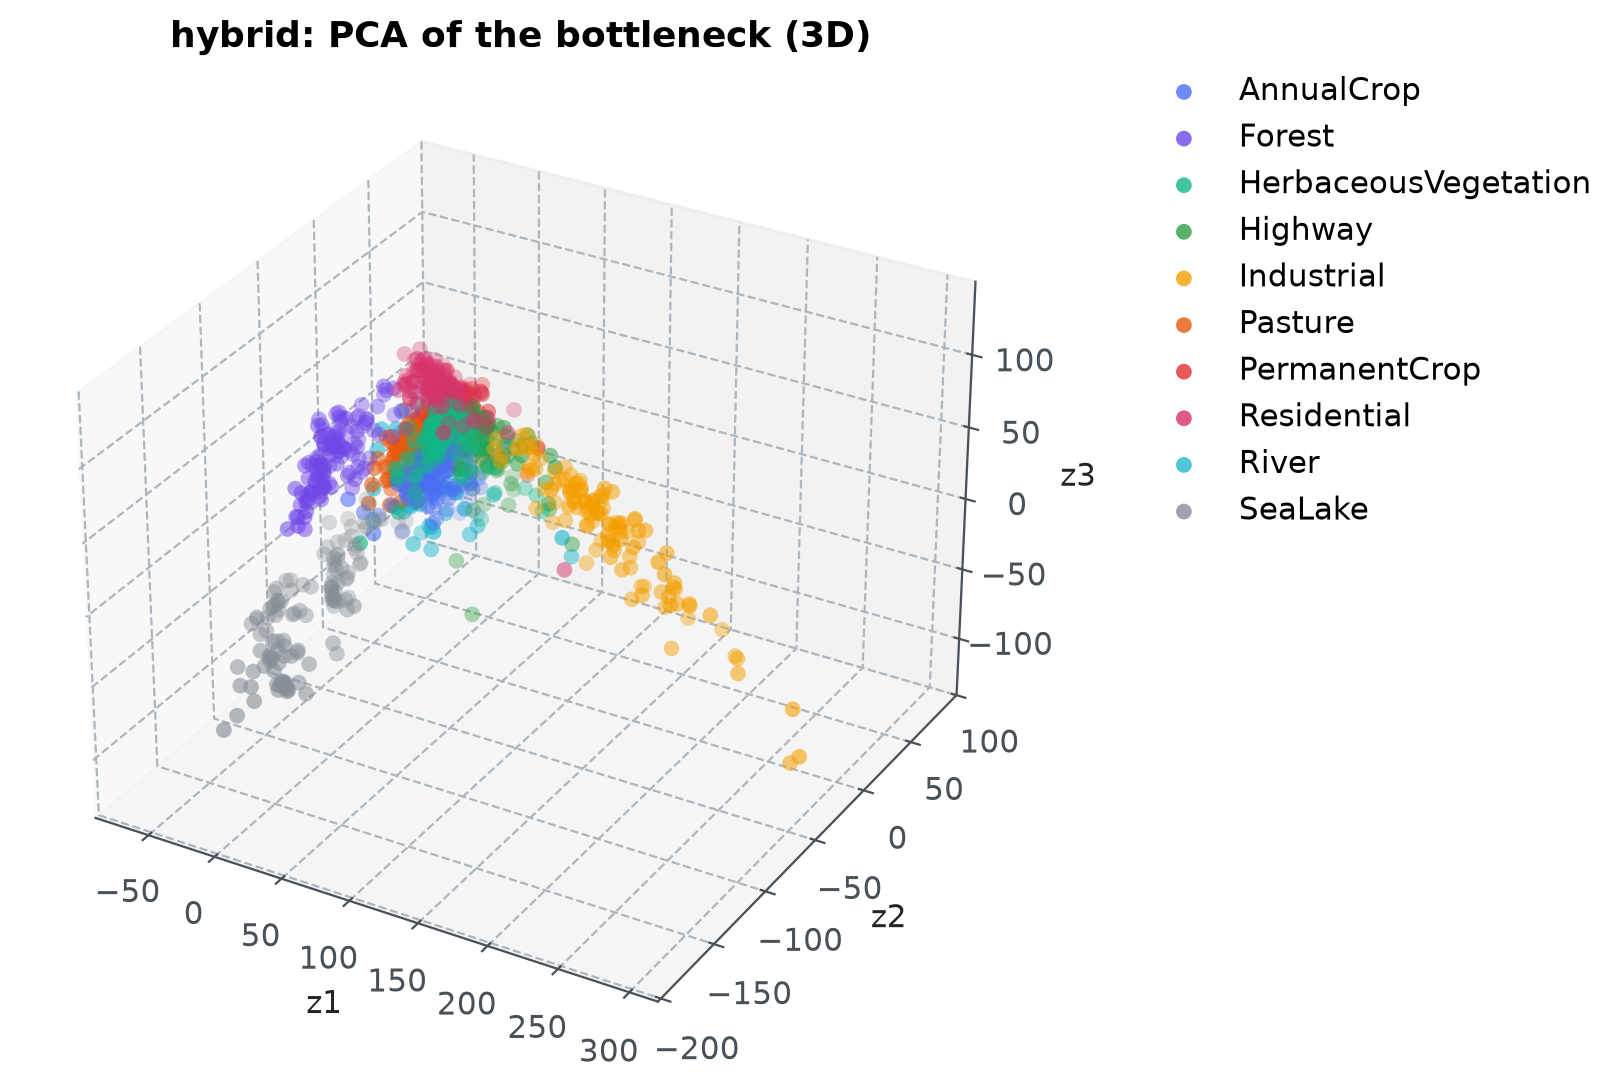

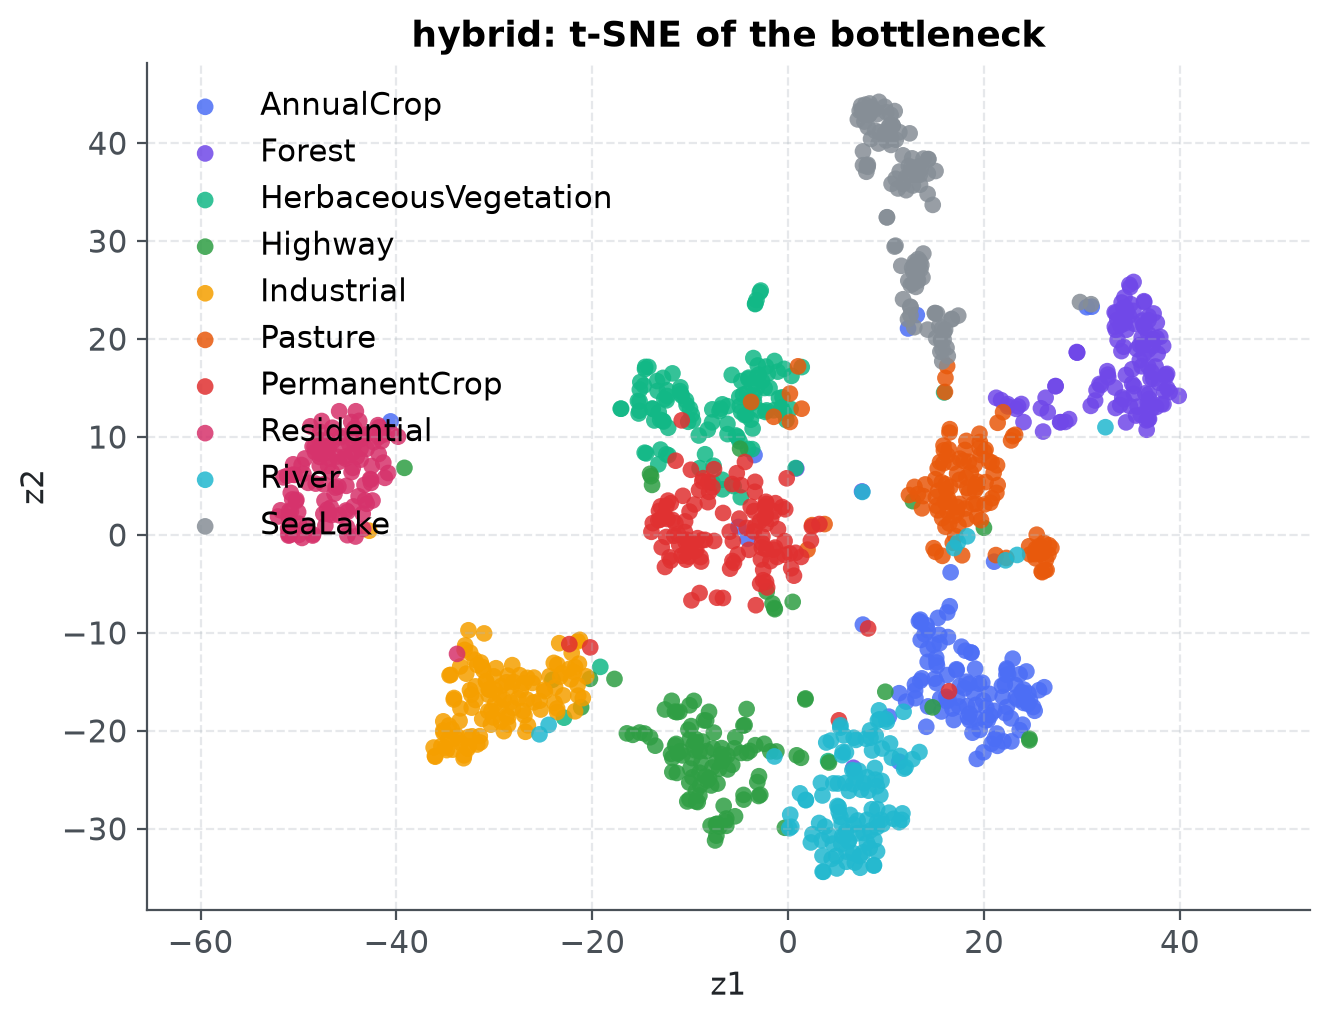

In [13]:
from sklearn.manifold import TSNE

from eos.utils.visualization import (
    plot_histogram_3d,
    plot_latent_projection,
    plot_latent_scatter_3d,
)

embeddings = {
    mode: np.load(EVIDENCE_DIR / f"embeddings_{mode}.npz") for mode in ("classifier", "hybrid")
}

for mode, data in embeddings.items():
    z = data["embeddings"]
    labels = data["labels"]
    centered = z - z.mean(axis=0)
    _, _, components = np.linalg.svd(centered, full_matrices=False)
    pca_2d = centered @ components[:2].T
    pca_3d = centered @ components[:3].T
    fig, ax = plot_latent_projection(
        pca_2d, labels, class_names=class_names, title=f"{mode}: PCA of the bottleneck"
    )
    figure_path = save_figure(fig, FIGURES_DIR / f"latent_pca2d_{mode}.png")
    display(Image(filename=str(figure_path)))

    fig, ax = plot_latent_scatter_3d(
        pca_3d, labels, class_names=class_names, title=f"{mode}: PCA of the bottleneck (3D)"
    )
    figure_path = save_figure(fig, FIGURES_DIR / f"latent_pca3d_{mode}.png")
    display(Image(filename=str(figure_path)))

    tsne_2d = TSNE(n_components=2, random_state=SEED, init="pca", perplexity=30).fit_transform(z)
    fig, ax = plot_latent_projection(
        tsne_2d, labels, class_names=class_names, title=f"{mode}: t-SNE of the bottleneck"
    )
    figure_path = save_figure(fig, FIGURES_DIR / f"latent_tsne_{mode}.png")
    display(Image(filename=str(figure_path)))

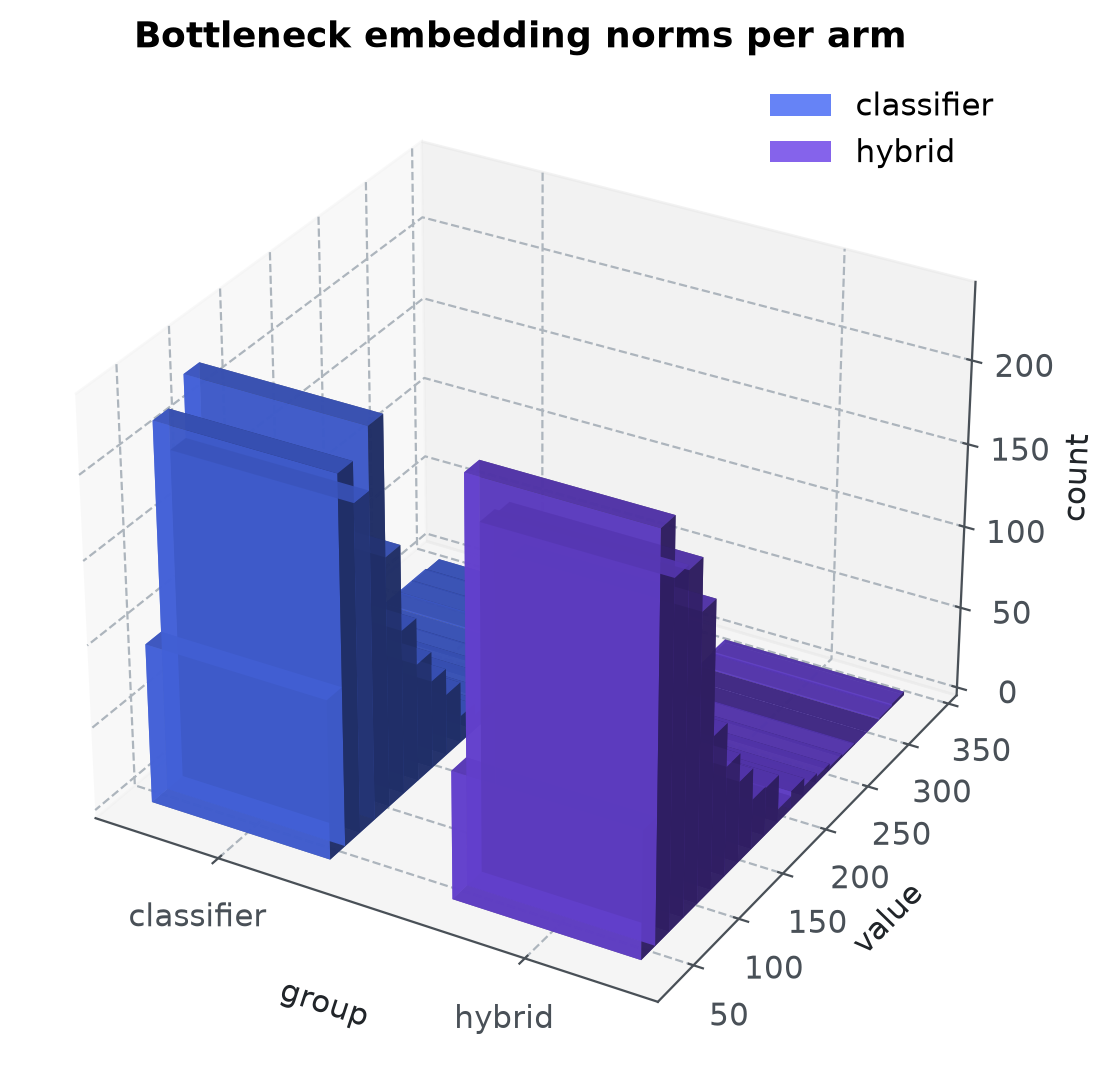

In [14]:
norms = [np.linalg.norm(data["embeddings"], axis=1) for data in embeddings.values()]

fig, ax = plot_histogram_3d(
    norms,
    group_names=list(embeddings),
    bins=20,
    title="Bottleneck embedding norms per arm",
)
figure_path = save_figure(fig, FIGURES_DIR / "embedding_norms_3d.png")
display(Image(filename=str(figure_path)))

## Loss trajectories

Per-epoch training curves as recorded by MLflow during the full-budget runs.

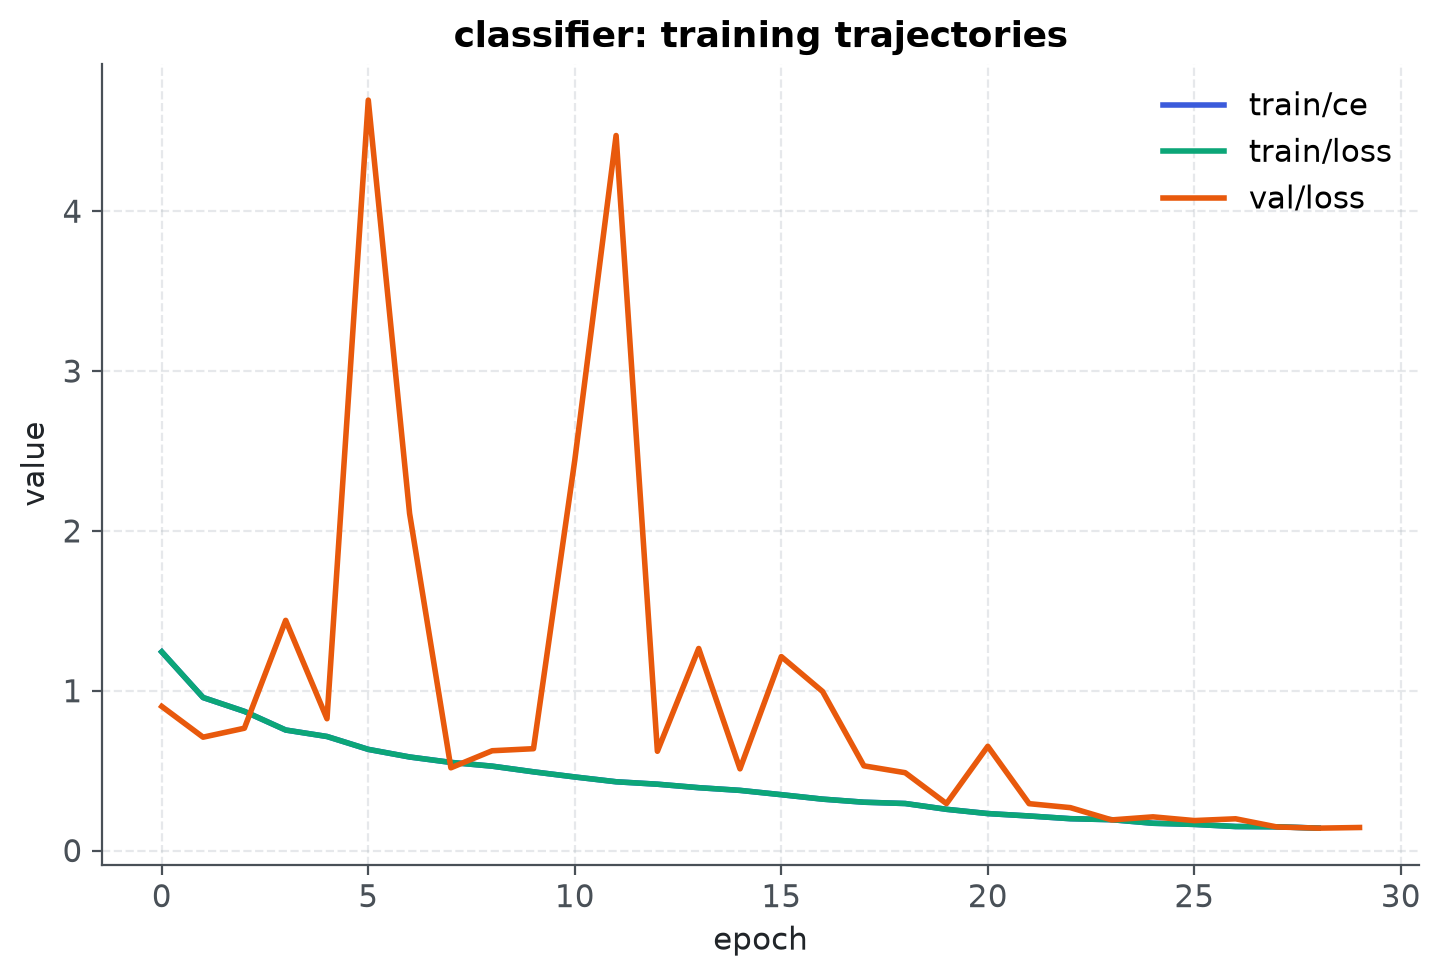

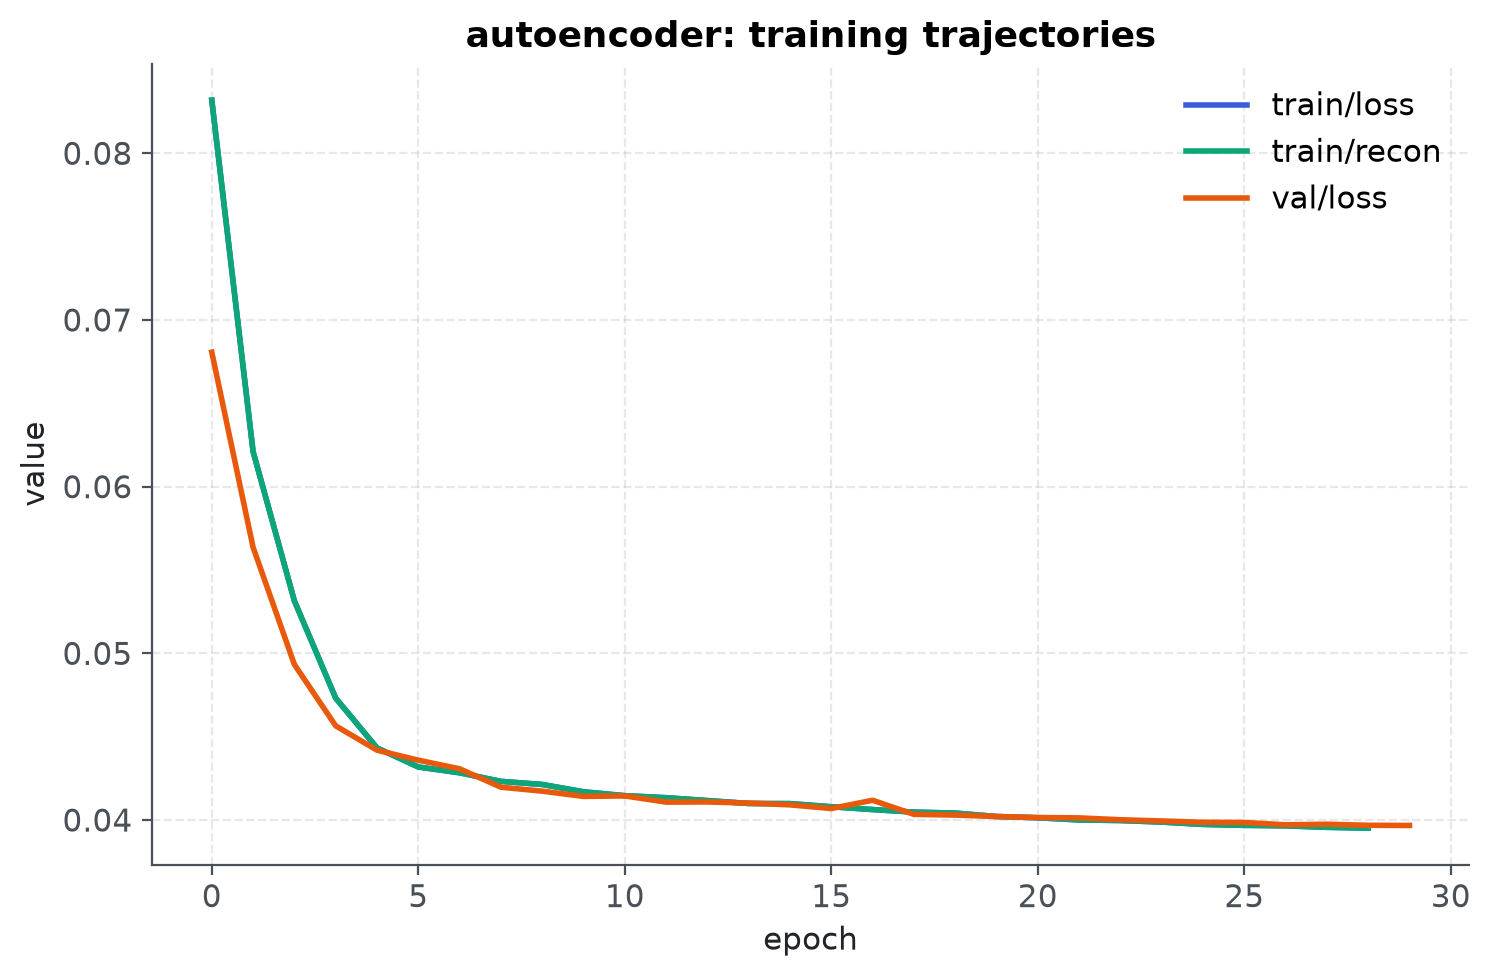

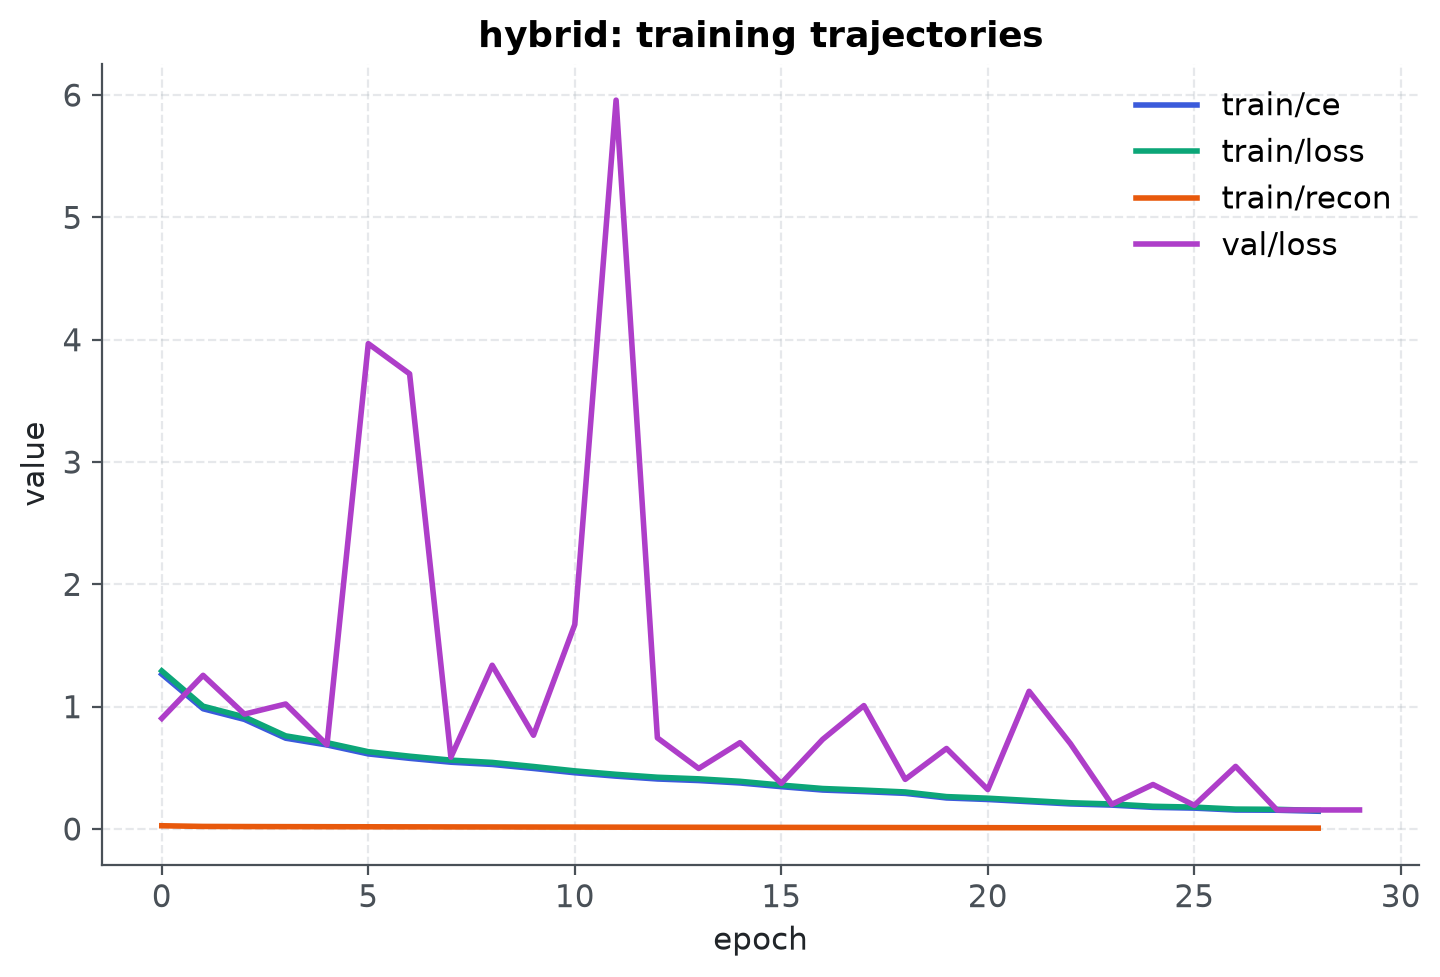

In [15]:
from eos.utils.visualization import plot_loss_trajectories

for mode in ("classifier", "autoencoder", "hybrid"):
    run = max(
        (r for r in bundle["runs"] if r["mode"] == mode and r["seed"] == 42),
        key=lambda r: r["run_name"],
    )
    history = {
        key: values
        for key, values in run["history"].items()
        if key in ("train/loss", "train/ce", "train/recon", "val/loss")
    }
    fig, ax = plot_loss_trajectories(history, title=f"{mode}: training trajectories")
    figure_path = save_figure(fig, FIGURES_DIR / f"loss_trajectories_{mode}.png")
    display(Image(filename=str(figure_path)))

## Training record

The evaluated checkpoints were produced by full-budget runs on the ROCm
container (AMD Radeon RX 9070 XT, `bf16-mixed`). Each arm ran as:

```bash
docker compose -f docker/docker-compose.yml --env-file .env --profile gpu \
  run --rm --no-deps eos-gpu uv run --no-sync \
  python -m eos.training.cli <hybrid|classifier|autoencoder> \
  --config configs/base.yaml --seed <42|7|123|2024>
```

**Trainer contract.** AdamW (lr 1e-3, weight decay 1e-4), linear warmup of 2
epochs into cosine decay, gradient clipping at 1.0, batch 128, 30 epochs, the
reconstruction weight $\lambda$ annealed 0.3 to 0.1, composite objective
$\mathrm{CE} + \lambda\,(0.85\,\mathrm{MSE} + 0.15\,(1-\mathrm{SSIM}))$ with the
masked-window SSIM (finding F-001). Every run logged parameters, per-epoch
metrics, the best checkpoint, and `metrics.json` to MLflow
(`http://localhost:5001`, experiment `eos-autoencoder`), and job wall/GPU times
to Prometheus (Grafana at `http://localhost:3001`).

The cell below runs the same pipeline for **one batch** so the notebook can
train end-to-end on a CPU budget; the results above never depend on it.

In [16]:
from eos.training.runner import run_experiment

if FAST_DEV_RUN:
    demo_train = config.train.model_copy(
        update={
            "fast_dev_run": True,
            "max_epochs": 1,
            "warmup_epochs": 0,
            "mlflow_enabled": False,
            "job_metrics_enabled": False,
            "checkpoint_dir": Path("checkpoints/demo"),
            "report_dir": Path("reports/training/demo"),
        }
    )
    demo_config = config.model_copy(update={"train": demo_train})
    demo = run_experiment("hybrid", demo_config)
    print(f"demo run complete: {demo.checkpoint_path}")
    demo_summary = {key: round(value, 4) for key, value in demo.metrics.items()}
    print(f"demo metrics: {demo_summary}")
else:
    print("full profile active: results come from the stored checkpoints; demo training skipped")

GPU available: False, used: False


TPU available: False, using: 0 TPU cores


💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


`Trainer(limit_train_batches=1)` was configured so 1 batch per epoch will be used.


`Trainer(limit_val_batches=1)` was configured so 1 batch will be used.


...

Restoring states from the checkpoint path at C:\Code\space encoder\checkpoints\demo\hybrid-00.ckpt


Loaded model weights from the checkpoint at C:\Code\space encoder\checkpoints\demo\hybrid-00.ckpt


C:\Code\space encoder\.venv\Lib\site-packages\lightning\pytorch\trainer\connectors\data_connector.py:434: The 'test_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=11` in the `DataLoader` to improve performance.


┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃        Test metric        ┃       DataLoader 0        ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│       test/accuracy       │            0.0            │
│          test/ce          │     2.247112512588501     │
│         test/loss         │    2.2707295417785645     │
│       test/macro_f1       │            0.0            │
│      test/recon_mse       │   0.026032015681266785    │
│     test/ssim_masked      │    0.6226925253868103     │
│      test/ssim_valid      │    0.6151726245880127     │
└───────────────────────────┴───────────────────────────┘

demo run complete: C:\Code\space encoder\checkpoints\demo\hybrid-00.ckpt
demo metrics: {'lr-AdamW': 0.001, 'val/ce': 2.2457, 'val/loss': 2.2689, 'val/accuracy': 0.0, 'val/macro_f1': 0.0, 'val/recon_mse': 0.0275, 'val/ssim_masked': 0.6403, 'val/ssim_valid': 0.6321, 'train/loss': 2.3708, 'train/ce': 2.3198, 'train/recon': 0.051, 'train/mse': 0.0455, 'train/ssim_loss': 0.8749, 'train/ssim_surrogate': 0.1251, 'train/recon_lambda': 0.3, 'test/ce': 2.2471, 'test/loss': 2.2707, 'test/accuracy': 0.0, 'test/macro_f1': 0.0, 'test/recon_mse': 0.026, 'test/ssim_masked': 0.6227, 'test/ssim_valid': 0.6152}


## Findings

**Verdict — directionally supported, not confirmed.** Across 4 seeds per arm
the Hybrid-CAE beats the Pure CNN on test macro-F1 in most pairs (mean paired
delta +0.0020 under bf16-mixed logging, +0.0034 under float32
re-evaluation), but the pair-level sign is not robust to evaluation precision
and n = 4 cannot clear significance (one-sided paired p ~ 0.07). Roughly 12
seeds per arm would be required to confirm an effect of this size.

**Mechanism — partially confirmed, relocated.** The per-class slice (F-003)
shows the gains concentrate in the cropland complex: HerbaceousVegetation
+0.0084, AnnualCrop +0.0061 (4/4 seeds), PermanentCrop +0.0042. The hypothesized
river/highway pair does not respond beyond noise (+0.0021, 2/4 seeds). The
defensible claim is that reconstruction regularization preserves *spatial-spectral
detail* — helping texture-discriminated classes — not that it preserves
boundary topology specifically.

**Measurement — the apparatus is at its resolution limit (F-002).** Identical
weights yield macro-F1 differences up to 0.0048 between bf16-mixed and float32
inference, and duplicate-seed trainings differ by 0.0015 on the same split.
The effect under test (~0.002-0.003) sits inside this floor; all comparisons in
this notebook are float32 and labelled as such.

**Reconstruction — unambiguous.** The autoencoder sets the ceiling (MSE
0.00255, valid SSIM 0.754); the hybrid decoder holds 0.0062 +/- 0.0001 MSE
across all seeds while carrying the classification head. The cost of the shared
latent is a factor of ~2.4 in reconstruction MSE — a stable, quantified
trade-off.

**Failure cases and limitations.**
- Per-class deltas have per-seed spreads up to +/-0.017; the class ranking is a trend, not an established order.
- Checkpoint selection maximizes validation macro-F1; part of the test advantage may be a selection interaction (validation deltas are mixed, 2/4).
- All numbers come from one dataset, one architecture family, and one hardware stack.
- The ASVD-compressed arm is Phase 4 work and is intentionally left pending in the ablation table.

**Next steps.** A ~12-seed confirmation run if the cropland slice matters for
the thesis claim; per-class analysis of the AnnualCrop <-> PermanentCrop
confusion specifically; then Phase 4 (ASVD on the bottleneck projections and
MMD drift telemetry).